# Emotion labels vs. VLM answers – four models

Same analysis as `compare_emotions_data_out.ipynb`, for the four model files:
`google__gemini-2.5-flash.csv`, `meta-llama__llama-4-maverick.csv`, `openai__gpt-4o-mini.csv`, `qwen__qwen2.5-vl-72b-instruct.csv`.

What this notebook adds:
* **Missing answers:** GPT-4o-mini returned no answers for some images. The notebook reports coverage, checks whether the missing images are biased towards particular labels, and computes all metrics twice: on all available answers, and on the **common subset** of images answered by every model.
* **Normalisation audit per model:** some models (Llama, GPT) answer in long sentences, so the keyword rules matter much more here.
* **Model comparison:** an exact McNemar test between models for each question, and agreement between models.

**Conventions**
* `dk` (don't know) and `unparsed` answers count as **wrong** in the main metrics. Their rates are reported separately.
* `missing` answers (no output from the model) are **excluded**, and the n per question is reported.
* Images labelled `unclear` are **excluded** from scoring and analysed separately.
* Ground truth: positive → Q1/Q2 = positive, Q3–Q5 = no, Q6–Q8 = yes; negative → negative / yes / no; neutral → none / no / no.

> **Note on the result boxes:** the "Result" sentences below each evaluation were written from the run on 2026-11-18, using the current data files and normalisation rules. If the data or rules change, re-run the notebook and update the sentences.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path(".")
sys.path.insert(0, str(DATA_DIR.resolve()))
import emotion_compare_utils as U

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

LABELS_FILE = DATA_DIR / "emotions_labels.csv"
QUESTIONS_FILE = DATA_DIR / "questions.txt"
MODEL_FILES = sorted(DATA_DIR.glob("*__*.csv"))  # provider__model.csv
OUTPUT_DIR = DATA_DIR / "comparison_results" / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
N_BOOT, SEED = 1000, 42

QMETA = U.load_questions(QUESTIONS_FILE)
print([f.name for f in MODEL_FILES])

['google__gemini-2.5-flash.csv', 'meta-llama__llama-4-maverick.csv', 'openai__gpt-4o-mini.csv', 'qwen__qwen2.5-vl-72b-instruct.csv']


## 1. Load and join

In [2]:
labels = U.load_labels(LABELS_FILE)
vqa = pd.concat([U.load_vqa(f) for f in MODEL_FILES], ignore_index=True)
# short model names for plots: 'openai/gpt-4o-mini' -> 'gpt-4o-mini'
vqa["model"] = vqa["model"].str.split("/").str[-1]
MODELS = list(vqa.model.unique())
data = U.join_labels(vqa, labels)
print("models:", MODELS)
data.groupby("model").size().rename("images")

labels: 300  vqa rows: 1200  filenames only in labels: 0  only in vqa: 0
models: ['gemini-2.5-flash', 'llama-4-maverick', 'gpt-4o-mini', 'qwen2.5-vl-72b-instruct']


model
gemini-2.5-flash           300
gpt-4o-mini                300
llama-4-maverick           300
qwen2.5-vl-72b-instruct    300
Name: images, dtype: int64

**What is calculated:** The four model files are loaded, the model names are shortened, and the answers are joined with the labels.

**Why:** All comparisons assume that every model answered the same images.

**How to compare:** Each model should have 300 rows and nothing should be left unmatched.

> **Result:** All four files contain all 300 images and match the labels one-to-one.

### 1a. Coverage / missing answers

In [3]:
miss = pd.DataFrame({q: data.groupby("model")[q].apply(lambda s: s.isna().sum()) for q in U.QIDS})
miss["images_with_any_missing"] = data.groupby("model")[U.QIDS].apply(lambda d: d.isna().any(axis=1).sum())
miss["images_all_missing"] = data.groupby("model")[U.QIDS].apply(lambda d: d.isna().all(axis=1).sum())
miss

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,images_with_any_missing,images_all_missing
model,,,,,,,,,,
gemini-2.5-flash,0,0,0,0,0,0,0,0,0,0
gpt-4o-mini,35,35,35,35,35,35,35,35,35,35
llama-4-maverick,0,0,0,0,0,0,0,0,0,0
qwen2.5-vl-72b-instruct,1,0,0,2,0,0,0,0,3,0


**What is calculated:** The number of missing answers per model and question, and the number of images with any or all answers missing.

**Why:** Missing answers are excluded from scoring, so different coverage can bias a comparison between models.

**How to compare:** 0 is ideal. Compare the models; images with *all* answers missing usually point to a failed API call rather than a refusal of one question.

> **Result:** GPT-4o-mini has no answers at all for 35 images (all 8 questions missing). Qwen lacks 3 single answers, and Gemini and Llama are complete.

In [4]:
# Are the missing images biased towards some labels or subfolders?
data["all_missing"] = data[U.QIDS].isna().all(axis=1)
for m in MODELS:
    d = data[data.model == m]
    if d.all_missing.any():
        print(f"--- {m}: {d.all_missing.sum()} images without answers")
        t = pd.crosstab(d.emotion, d.all_missing, margins=True)
        t.columns = [{False: "answered", True: "missing"}.get(c, c) for c in t.columns]
        display(t)
        display(pd.crosstab(d.subfolder, d.all_missing).rename(columns={False: "answered", True: "missing"}))
        miss_files = d.loc[d.all_missing, ["filename", "emotion", "subfolder"]]
        miss_files.to_csv(OUTPUT_DIR / f"missing_{U.safe_name(m)}.csv", index=False)

--- gpt-4o-mini: 35 images without answers


,answered,missing,All
emotion,,,
negative,94,5,99
neutral,67,17,84
positive,89,10,99
unclear,15,3,18
All,265,35,300


all_missing,answered,missing
subfolder,,
(none),15,3
folder1,107,0
folder2,39,27
neutral_vis_negative_text,28,0
neutral_vis_positive_text,10,0
nonviolent_1,19,0
nonviolent_2,7,2
violent_1,33,0
violent_2,7,3


**What is calculated:** The label and subfolder distribution of the images without answers.

**Why:** If the missing images are not random, a model's metrics refer to an easier or harder subset of images.

**How to compare:** Compare the share of missing images per label or subfolder with the overall share (35/300 ≈ 12%).

> **Result:** The missing GPT images are not random: 27 of the 35 come from `folder2` (41% of that folder) and 17 are neutral. Model comparisons should therefore use the common subset (section 3).

## 2. Normalise answers

### Normalisation rules (`emotion_compare_utils.py`)
Every answer gets a category **and the rule that produced it** (`Qx_rule`), so the mapping can be audited.

| rule | applies to | example → category |
|---|---|---|
| `exact` | the whole answer is a category | "Yes." → yes, "Neutral" → none, "No" (to Q1) → none |
| `first` | the first word is a category | "No, the picture does not …" → no |
| `answer_is` | explicit conclusion (the last one counts) | "… Therefore, the correct answer is: negative." → negative |
| `kw_negated` | Q3–Q8: the emotion asked about is negated | "The image does not show any negative emotional content" → no (Q3) |
| `kw_dk` | hedging | "… difficult to determine …", "cannot be assessed", "too blurry" → dk |
| `kw_affirm` | Q3–Q8: the emotion asked about, or a synonym, is mentioned | "… indicating a positive emotional tone" → yes (Q6) |
| `kw_opposite` | Q3–Q8: only the opposite emotion or "no emotion" is mentioned | "two men smiling, positive tone" → no (Q3) |
| `kw_both` | Q1/Q2 | "a mix of emotions", "both positive and negative" → both |
| `kw_none` | Q1/Q2 | "does not show any (positive or negative) emotional content" → none |
| `kw_none_however` | Q1/Q2 | "… itself shows no emotion. However, the text suggests a negative …" → negative |
| `kw_neutral` | Q1/Q2 | "neutral" in the first sentence with no polarity word → none |
| `kw_polarity` | Q1/Q2 | first non-negated emotion keyword (negative: somber, tense, distress, …; positive: smiling, joy, …) → that polarity |
| `unparsed` | nothing matched | counted as wrong |

The keyword rules are heuristics. **Check the review tables below** before reading the metrics. If a mapping is wrong, change the rules in the module; both notebooks pick the change up.

In [5]:
data = U.normalise(data, QMETA)
rc = U.rule_counts(data)
rc.to_csv(OUTPUT_DIR / "rule_counts.csv")
# share of answers that needed keyword rules (i.e. were not exact / first word / missing)
kw_cols = [c for c in rc.columns if c.startswith("kw_") or c in ("answer_is", "unparsed")]
share = (rc[kw_cols].sum(axis=1) / rc.drop(columns="missing", errors="ignore").sum(axis=1)).unstack("model")
print("Share of answered items mapped by keyword rules:")
display(share.round(2))
rc

Share of answered items mapped by keyword rules:


model,gemini-2.5-flash,gpt-4o-mini,llama-4-maverick,qwen2.5-vl-72b-instruct
qid,,,,
Q1,0.62,1.00,1.00,0.65
Q2,0.00,0.00,0.25,0.00
Q3,0.00,0.23,0.60,0.00
Q4,0.00,0.00,0.00,0.00
Q5,0.00,0.00,0.01,0.00
Q6,0.00,0.41,0.69,0.00
Q7,0.00,0.00,0.00,0.00
Q8,0.00,0.00,0.00,0.00


answer_is  exact  first  kw_affirm  kw_both  kw_dk  kw_negated  kw_neutral  kw_none  kw_none_however  kw_opposite  kw_polarity  missing  unparsed
qid model                                                                                                                                                                     
Q1  gemini-2.5-flash                 0    107      6          0        0      0           0           3       70                3            0          111        0         0
    gpt-4o-mini                      0      0      0          0        2      6           0          32       20                0            0          205       35         0
    llama-4-maverick                 1      0      0          0        2      9           0          12       55                0            0          221        0         0
    qwen2.5-vl-72b-instruct          0    105      0          0        0      0           0           1       65                1            0          127        1         0
Q2  gemini-2.5-flash                 0    300      0          0        0      0           0           0        0                0            0            0        0         0
    gpt-4o-mini                      0    264      0          0        0      0           0           0        0                0            0            1       35         0
    llama-4-maverick                41    224      0          0        2      0           0           1        2                0            0           30        0         0
    qwen2.5-vl-72b-instruct          0    300      0          0        0      0           0           0        0                0            0            0        0         0
Q3  gemini-2.5-flash                 0      7    293          0        0      0           0           0        0                0            0            0        0         0
    gpt-4o-mini                      0      0    205         11        0      9          37           0        0                0            2            0       35         1
    llama-4-maverick                 4      7    112         44        0      0         131           0        0                0            2            0        0         0
    qwen2.5-vl-72b-instruct          0    277     23          0        0      0           0           0        0                0            0            0        0         0
Q4  gemini-2.5-flash                 0    300      0          0        0      0           0           0        0                0            0            0        0         0
    gpt-4o-mini                      0    265      0          0        0      0           0           0        0                0            0            0       35         0
    llama-4-maverick                 0    300      0          0        0      0           0           0        0                0            0            0        0         0
    qwen2.5-vl-72b-instruct          0    298      0          0        0      0           0           0        0                0            0            0        2         0
Q5  gemini-2.5-flash                 0    300      0          0        0      0           0           0        0                0            0            0        0         0
    gpt-4o-mini                      0    265      0          0        0      0           0           0        0                0            0            0       35         0
    llama-4-maverick                 1    297      0          0        0      0           2           0        0                0            0            0        0         0
    qwen2.5-vl-72b-instruct          0    300      0          0        0      0           0           0        0                0            0            0        0         0
Q6  gemini-2.5-flash                 0     30    269          0        0      1           0           0        0                0            0            0        0         0
    

**What is calculated:** For each model and question: the counts per normalisation rule, and the share of answered items that needed a keyword rule.

**Why:** The more free text a model produces, the more its metrics depend on the heuristic rules.

**How to compare:** A share near 0 means the model followed the answer format. A high share means its results for that question should be read together with the review table.

> **Result:** Gemini and Qwen follow the format of the constrained prompts and need keyword rules mainly for Q1 (≈ 0.6). GPT and Llama answer Q1 entirely in free text and Q3/Q6 in 23–69% of cases, so their open-question results depend most on the rules. One answer remains unparsed.

In [6]:
review = U.mapping_review(data, rules=["answer_is", "kw_negated", "kw_dk", "kw_affirm", "kw_opposite",
                                       "kw_both", "kw_none", "kw_none_however", "kw_neutral", "kw_polarity", "unparsed"])
review.to_csv(OUTPUT_DIR / "mapping_review.csv", index=False)
print(f"{len(review)} distinct keyword-mapped answers (full list in {OUTPUT_DIR / 'mapping_review.csv'})")
# random sample per model and rule for a quick check
(review.sample(frac=1, random_state=SEED).groupby(["model", "rule"]).head(4)
       .sort_values(["model", "rule"])[["model", "qid", "rule", "normalised", "raw"]])

1417 distinct keyword-mapped answers (full list in comparison_results/models/mapping_review.csv)


,model,qid,rule,normalised,raw
155,gemini-2.5-flash,Q6,kw_dk,dk,"It is difficult to definitively determine the emotional content of the image as it depicts a large crowd with many red flares or smoke, which can be associated with both celebratory events (like s..."
2,gemini-2.5-flash,Q1,kw_neutral,none,"The man in the picture appears to be speaking at an event, possibly a conference or a press briefing. His expression is neutral, and there are no clear indicators of positive or negative emotional..."
0,gemini-2.5-flash,Q1,kw_neutral,none,The man in the picture appears to have a neutral or slightly contemplative expression. There is no strong indication of positive or negative emotional content.
1,gemini-2.5-flash,Q1,kw_neutral,none,The man in the picture appears to be in a **neutral to slightly pensive** emotional state. There's no strong indication of positive or negative emotion.
51,gemini-2.5-flash,Q1,kw_none,none,"No, the picture does not show any strong positive or negative emotional content. The lion cub and the bird appear neutral."
67,gemini-2.5-flash,Q1,kw_none,none,"No, the picture does not show any clear positive or negative emotional content. The person in the background is out of focus, making it impossible to discern their expression. The foreground shows..."
49,gemini-2.5-flash,Q1,kw_none,none,"The picture does not clearly show any strong positive or negative emotional content. The man's expression is somewhat obscured by his beard and goggles, and while his mouth is slightly open, it's ..."
29,gemini-2.5-flash,Q1,kw_none,none,"No, the picture does not show any positive or negative emotional content. It's an aerial shot of a landscape with text overlay."
70,gemini-2.5-flash,Q1,kw_none_however,negative,"The image itself does not inherently show strong positive or negative emotional content. It depicts a formal arrival or departure, likely a diplomatic event, with individuals posing for a photogra..."
72,gemini-2.5-flash,Q1,kw_none_however,negative,"The picture itself does not show any explicit positive or negative emotional content. It depicts a street scene with buildings and a person on a bicycle. However, the text overlay ""Enfants livrés ..."


**What is calculated:** A random sample of up to 4 keyword-mapped answers per model and rule. The full list of 1,417 distinct answers is saved to `mapping_review.csv`.

**Why:** This is the manual check of the heuristics; a wrong mapping becomes a wrong prediction.

**How to compare:** Read `raw` against `normalised`. Change the rules in `emotion_compare_utils.py` if a pattern is mapped wrongly.

> **Result:** In the samples the category matches the meaning of the answer. The remaining borderline cases are hedged answers such as "neutral or slightly negative" (→ none) or "could suggest negative … but difficult to determine" (→ dk).

In [7]:
dist = U.answer_distribution(data)
dist

positive  negative  both  none   dk  yes   no  unparsed  missing
qid model                                                                                    
Q1  gemini-2.5-flash               91       100     0   109    0    0    0         0        0
    gpt-4o-mini                    92       113     2    52    6    0    0         0       35
    llama-4-maverick               93       128     2    68    9    0    0         0        0
    qwen2.5-vl-72b-instruct        98        95     0   106    0    0    0         0        1
Q2  gemini-2.5-flash               90       100     4    83   23    0    0         0        0
    gpt-4o-mini                    76        94     5    14   76    0    0         0       35
    llama-4-maverick               93       106    32    69    0    0    0         0        0
    qwen2.5-vl-72b-instruct        87        84     3    83   43    0    0         0        0
Q3  gemini-2.5-flash                0         0     0     0    0   98  202         0        0
    gpt-4o-mini                     0         0     0     0    9  103  152         1       35
    llama-4-maverick                0         0     0     0    0  103  197         0        0
    qwen2.5-vl-72b-instruct         0         0     0     0    0   73  227         0        0
Q4  gemini-2.5-flash                0         0     0     0   25   97  178         0        0
    gpt-4o-mini                     0         0     0     0   68   89  108         0       35
    llama-4-maverick                0         0     0     0    0  113  187         0        0
    qwen2.5-vl-72b-instruct         0         0     0     0  211   37   50         0        2
Q5  gemini-2.5-flash                0         0     0     0    2  133  165         0        0
    gpt-4o-mini                     0         0     0     0   35  103  127         0       35
    llama-4-maverick                0         0     0     0    0  107  193         0        0
    qwen2.5-vl-72b-instruct         0         0     0     0  164   60   76         0        0
Q6  gemini-2.5-flash                0         0     0     0    1   92  207         0        0
    gpt-4o-mini                     0         0     0     0   16   98  151         0       35
    llama-4-maverick                0         0     0     0    1  105  194         0        0
    qwen2.5-vl-72b-instruct         0         0     0     0    0   91  209         0        0
Q7  gemini-2.5-flash                0         0     0     0   64   91  145         0        0
    gpt-4o-mini                     0         0     0     0   79   86  100         0       35
    llama-4-maverick                0         0     0     0    0  110  190         0        0
    qwen2.5-vl-72b-instruct         0         0     0     0  201   76   23         0        0
Q8  gemini-2.5-flash                0         0     0     0   31   89  180         0        0
    gpt-4o-mini                     0         0     0     0   54   92  119         0       35
    llama-4-maverick                0         0     0     0    0   92  208         0        0
    qwen2.5-vl-72b-instruct         0         0     0     0  183   72   45         0        0

**What is calculated:** How often each normalised answer occurs, per model and question.

**Why:** It shows each model's response bias (e.g. reluctance to say "none", or many DK answers) before any comparison with the labels.

**How to compare:** Compare with the labels: 84 neutral images should give about 84 "none" for Q1/Q2, and about 99 "yes" for the negative and positive yes/no questions.

> **Result:** The response styles differ strongly. Qwen answers DK 164–211 times on Q4/Q5/Q7/Q8, Llama never says DK but uses "both" 32 times in Q2, and Gemini says "yes" to the negative cue question Q5 133 times (more than the 99 negative images).

## 3. Long table and common subset

In [8]:
long = U.to_long(data, QMETA)
# common subset: images where every model has a (non-missing) answer to that question
answered = long[long.pred != "missing"].groupby(["qid", "filename"]).model.nunique()
common = answered[answered == len(MODELS)].reset_index()[["qid", "filename"]]
long["in_common"] = long.set_index(["qid", "filename"]).index.isin(common.set_index(["qid", "filename"]).index)
long.to_csv(OUTPUT_DIR / "comparison_long.csv", index=False)
print("common-subset images per question:", common.groupby("qid").size().to_dict())

common-subset images per question: {'Q1': 264, 'Q2': 265, 'Q3': 265, 'Q4': 263, 'Q5': 265, 'Q6': 265, 'Q7': 265, 'Q8': 265}


**What is calculated:** For each question, the images answered by all four models (the common subset).

**Why:** Comparing models on different images would mix model differences with image differences.

**How to compare:** Use the common subset for model comparisons, and all available answers when describing each model on its own.

> **Result:** 263–265 images per question are answered by all four models (248–250 after excluding *unclear*).

## 4. Metrics per model and question
`summary_all` uses every available answer; `summary_common` uses only images answered by all models. Use `summary_common` to compare models directly.

`accuracy` counts `dk` as wrong. `acc_answered` is the accuracy when the model commits to an answer. Some models answer DK very often for the constrained prompts ("Do not guess"), so always read the two together with `dk_rate`.

In [9]:
summary_all = U.question_metrics(long, n_boot=N_BOOT, seed=SEED)
summary_common = U.question_metrics(long[long.in_common], n_boot=N_BOOT, seed=SEED)
summary_all.to_csv(OUTPUT_DIR / "metrics_summary_all.csv", index=False)
summary_common.to_csv(OUTPUT_DIR / "metrics_summary_common.csv", index=False)
summary_common.round(3)

,model,qid,target,style,n_images,n_scored,n_missing,dk_rate,unparsed_rate,accuracy,acc_answered,macro_f1,kappa,acc_lo,acc_hi,f1_lo,f1_hi,yes_precision,yes_recall,yes_f1
0,gemini-2.5-flash,Q1,polarity,open,264,249,0,0.000,0.000,0.847,0.847,0.846,0.772,0.799,0.892,0.799,0.891,NaN,NaN,NaN
1,llama-4-maverick,Q1,polarity,open,264,249,0,0.028,0.000,0.771,0.793,0.767,0.656,0.719,0.823,0.710,0.818,NaN,NaN,NaN
2,gpt-4o-mini,Q1,polarity,open,264,249,0,0.024,0.000,0.815,0.835,0.806,0.722,0.767,0.860,0.752,0.857,NaN,NaN,NaN
3,qwen2.5-vl-72b-instruct,Q1,polarity,open,264,249,0,0.000,0.000,0.847,0.847,0.845,0.771,0.799,0.892,0.795,0.886,NaN,NaN,NaN
4,gemini-2.5-flash,Q2,polarity,constrained,265,250,0,0.084,0.000,0.804,0.878,0.836,0.717,0.752,0.856,0.786,0.879,NaN,NaN,NaN
5,llama-4-maverick,Q2,polarity,constrained,265,250,0,0.000,0.000,0.768,0.768,0.796,0.664,0.716,0.820,0.745,0.843,NaN,NaN,NaN
6,gpt-4o-mini,Q2,polarity,constrained,265,250,0,0.288,0.000,0.656,0.921,0.681,0.540,0.596,0.716,0.625,0.733,NaN,NaN,NaN
7,qwen2.5-vl-72b-instruct,Q2,polarity,constrained,265,250,0,0.148,0.000,0.744,0.873,0.794,0.642,0.688,0.800,0.745,0.841,NaN,NaN,NaN
8,gemini-2.5-flash,Q3,negative,open,265,250,0,0.000,0.000,0.904,0.904,0.896,0.792,0.864,0.940,0.852,0.933,0.907,0.830,0.867
9,llama-4-maverick,Q3,negative,open,265,250,0,0.000,0.000,0.904,0.904,0.897,0.794,0.864,0.940,0.853,0.936,0.889,0.851,0.870


**What is calculated:** The same metrics as in notebook 1 (accuracy, `acc_answered`, macro-F1, κ, CIs, DK rate, P/R/F1 of "yes"), per model and question, on the common subset.

**Why:** These are the main numbers for comparing models and prompt variants.

**How to compare:** Within a question, compare models directly. Across questions, use κ, because the majority baselines differ (0.35 for the polarity questions, 0.65 for yes/no). Always read accuracy together with `dk_rate`. κ guide: < 0.4 fair, 0.4–0.6 moderate, 0.6–0.8 substantial, > 0.8 almost perfect agreement.

> **Result:** On the open questions Q3 and Q6 all four models are close (accuracy 0.87–0.93). On the constrained prompts they diverge strongly, from Llama (0.89–0.94 on Q4/Q7/Q8) down to Qwen (0.34–0.48 on Q4/Q5/Q7/Q8).

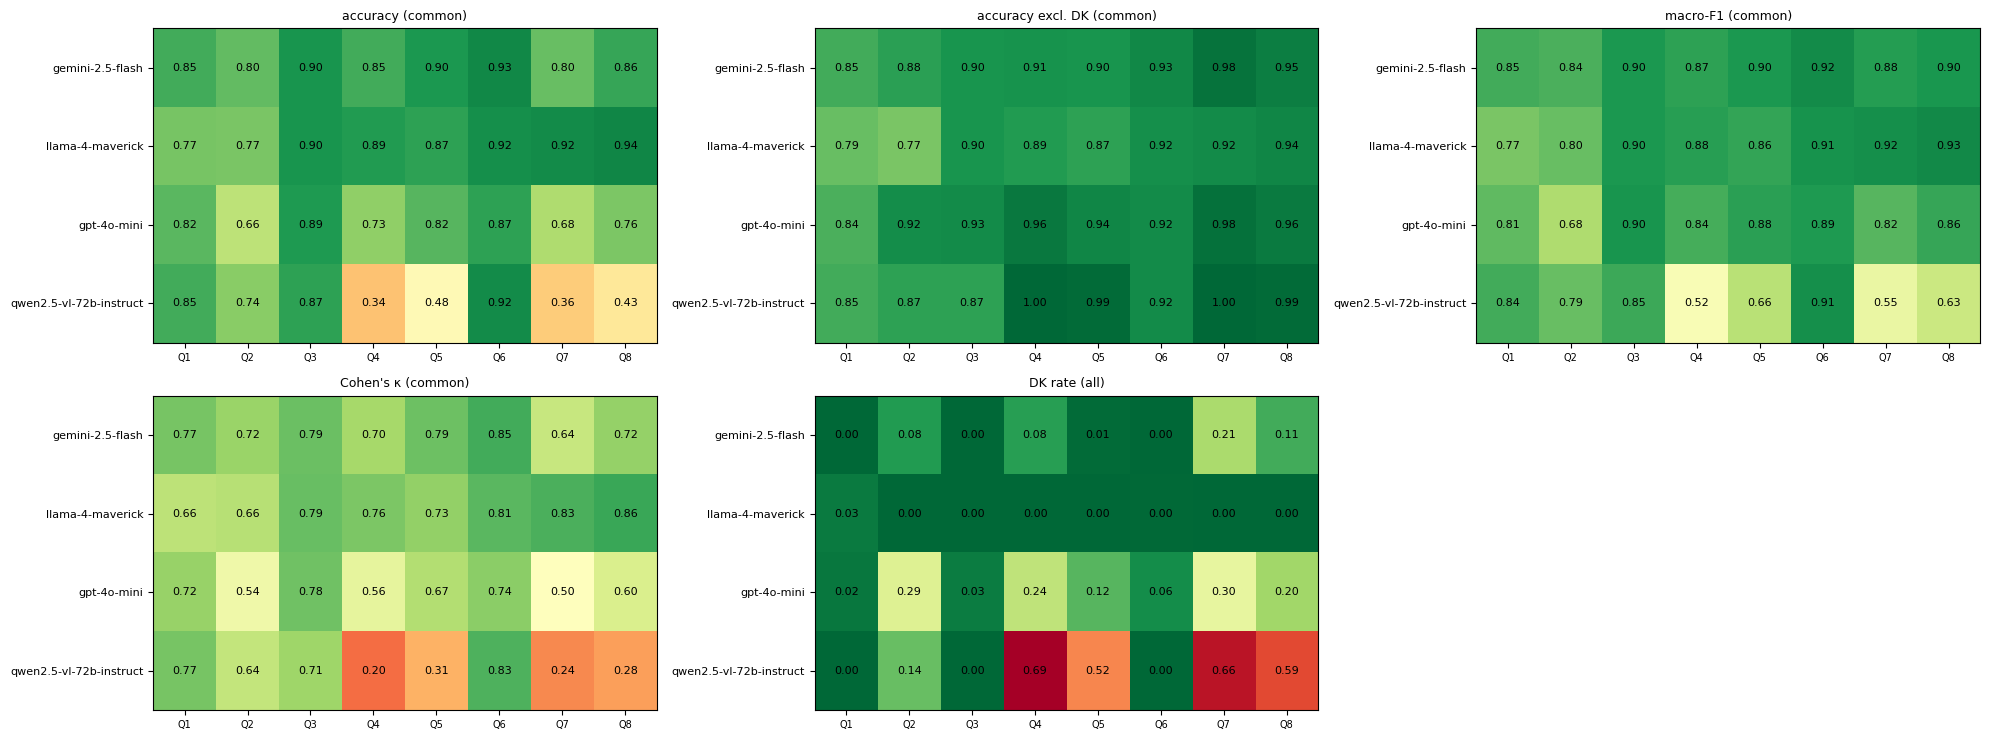

,,n_scored,accuracy,n_scored_common,accuracy_common,acc_diff_all_minus_common
model,qid,,,,,
gemini-2.5-flash,Q1,282,0.844,249,0.847,-0.003
llama-4-maverick,Q1,282,0.766,249,0.771,-0.005
gpt-4o-mini,Q1,250,0.816,249,0.815,0.001
qwen2.5-vl-72b-instruct,Q1,281,0.847,249,0.847,-0.000
gemini-2.5-flash,Q2,282,0.801,250,0.804,-0.003
llama-4-maverick,Q2,282,0.770,250,0.768,0.002
qwen2.5-vl-72b-instruct,Q2,282,0.752,250,0.744,0.008
gemini-2.5-flash,Q3,282,0.901,250,0.904,-0.003
llama-4-maverick,Q3,282,0.904,250,0.904,0.000


In [10]:
# Compact overview: accuracy / macro-F1 / kappa (common subset), and the effect of using all answers instead
fig, axes = plt.subplots(2, 3, figsize=(20, 7.5))
axes.flat[-1].axis("off")
for ax, (metric, src, title) in zip(axes.flat, [("accuracy", summary_common, "accuracy (common)"),
                                           ("acc_answered", summary_common, "accuracy excl. DK (common)"),
                                           ("macro_f1", summary_common, "macro-F1 (common)"),
                                           ("kappa", summary_common, "Cohen's κ (common)"),
                                           ("dk_rate", summary_all, "DK rate (all)")]):
    mat = src.pivot(index="model", columns="qid", values=metric).reindex(index=MODELS, columns=U.QIDS)
    U.plot_heatmap(mat, title, ax, cmap="RdYlGn_r" if metric == "dk_rate" else "RdYlGn",
                   vmax=max(mat.max().max(), 0.05) if metric == "dk_rate" else 1, fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "overview_heatmaps.png", dpi=150)
plt.show()

d = (summary_all.set_index(["model", "qid"])[["n_scored", "accuracy"]]
     .join(summary_common.set_index(["model", "qid"])[["n_scored", "accuracy"]], rsuffix="_common"))
d["acc_diff_all_minus_common"] = d["accuracy"] - d["accuracy_common"]
d[d.n_scored != d.n_scored_common].round(3)

**What is calculated:** Heatmaps of model × question for accuracy, accuracy without DK, macro-F1, κ (common subset) and the DK rate (all answers). The table below them shows how much accuracy changes between all available answers and the common subset.

**Why:** One overview of all models and questions. Comparing accuracy with accuracy-without-DK separates *not knowing* from *being wrong*.

**How to compare:** Low accuracy with high `acc_answered` means the model abstains (high DK rate) rather than errs. Small all-vs-common differences mean that missing answers do not bias the results.

> **Result:** The low constrained-prompt accuracy of Qwen (and partly GPT) is caused by DK: Qwen answers DK in 51–69% of Q4/Q5/Q7/Q8, but when it answers it is right in 99–100% of cases. Restricting to the common subset changes accuracy by at most 0.04.

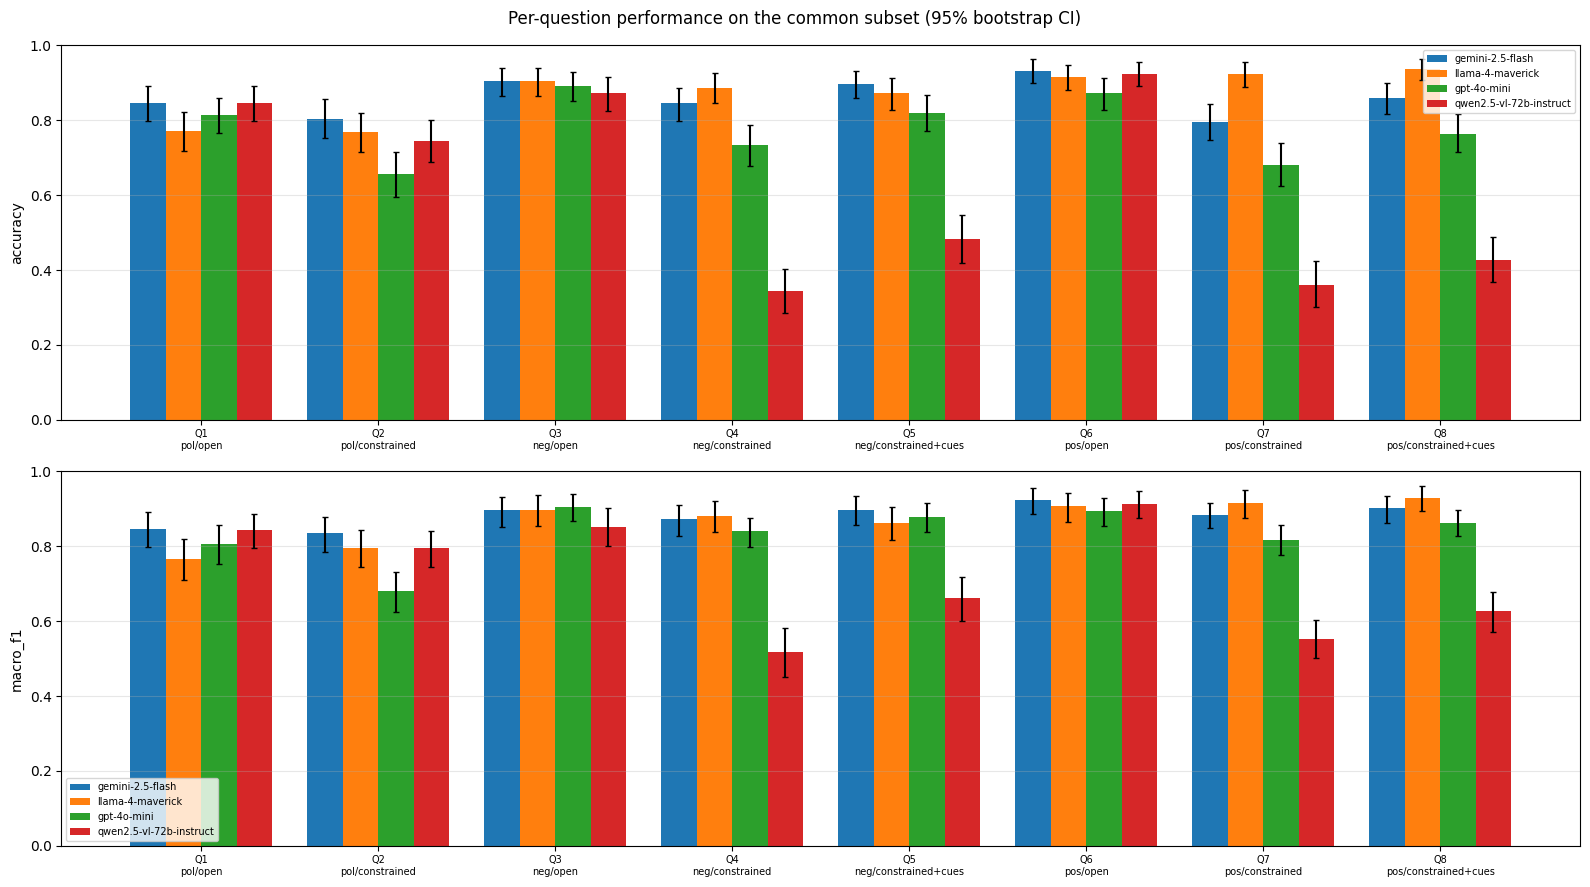

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(16, 9))
U.plot_metric_bars(summary_common, "accuracy", "acc_lo", "acc_hi", axes[0])
U.plot_metric_bars(summary_common, "macro_f1", "f1_lo", "f1_hi", axes[1])
fig.suptitle("Per-question performance on the common subset (95% bootstrap CI)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "metrics_bars_common.png", dpi=150)
plt.show()

**What is calculated:** Accuracy and macro-F1 per question with 95% bootstrap CIs, one bar per model (common subset).

**Why:** A visual check of which model differences exceed the sampling uncertainty.

**How to compare:** Non-overlapping intervals indicate a clear difference. For a formal test use the paired McNemar test (section 5a).

> **Result:** Llama is best on the constrained positive prompts (Q7 0.92, Q8 0.94), Gemini and Qwen share the best Q1 (0.85), and Gemini has the best Q6 (0.93). On Q3 the intervals of all four models overlap.

In [12]:
# yes/no questions: precision / recall / F1 for 'yes' (common subset)
summary_common[summary_common.target != "polarity"].pivot(
    index="model", columns="qid", values=["yes_precision", "yes_recall", "yes_f1"]).round(2)

yes_precision                               yes_recall                               yes_f1                              
qid                                Q3    Q4    Q5    Q6    Q7    Q8         Q3    Q4    Q5    Q6    Q7    Q8     Q3    Q4    Q5    Q6    Q7    Q8
model                                                                                                                                            
gemini-2.5-flash                 0.91  0.90  0.82  0.99  1.00  0.97       0.83  0.83  0.95  0.82  0.83  0.83   0.87  0.86  0.88  0.90  0.91  0.90
gpt-4o-mini                      0.86  0.93  0.87  0.89  0.96  0.94       0.91  0.85  0.94  0.88  0.83  0.88   0.89  0.89  0.90  0.88  0.89  0.91
llama-4-maverick                 0.89  0.84  0.83  0.91  0.90  0.97       0.85  0.87  0.83  0.84  0.89  0.84   0.87  0.85  0.83  0.88  0.89  0.90
qwen2.5-vl-72b-instruct          0.97  1.00  0.98  0.96  1.00  1.00       0.68  0.38  0.56  0.82  0.76  0.72   0.80  0.55  0.72  0.88  0.87  0.84

**What is calculated:** Precision, recall and F1 of "yes" for the yes/no questions (common subset).

**Why:** Precision measures false alarms ("yes" for images without that emotion), recall measures misses. DK lowers recall.

**How to compare:** High precision with low recall means a cautious model; the reverse means a trigger-happy one. F1 balances both.

> **Result:** Qwen has almost perfect precision (0.96–1.00) but low recall on the constrained negative prompts (Q4 0.38, Q5 0.56). The other models balance both (F1 0.83–0.91).

### Confusion matrices (all available answers; rows include *unclear*)

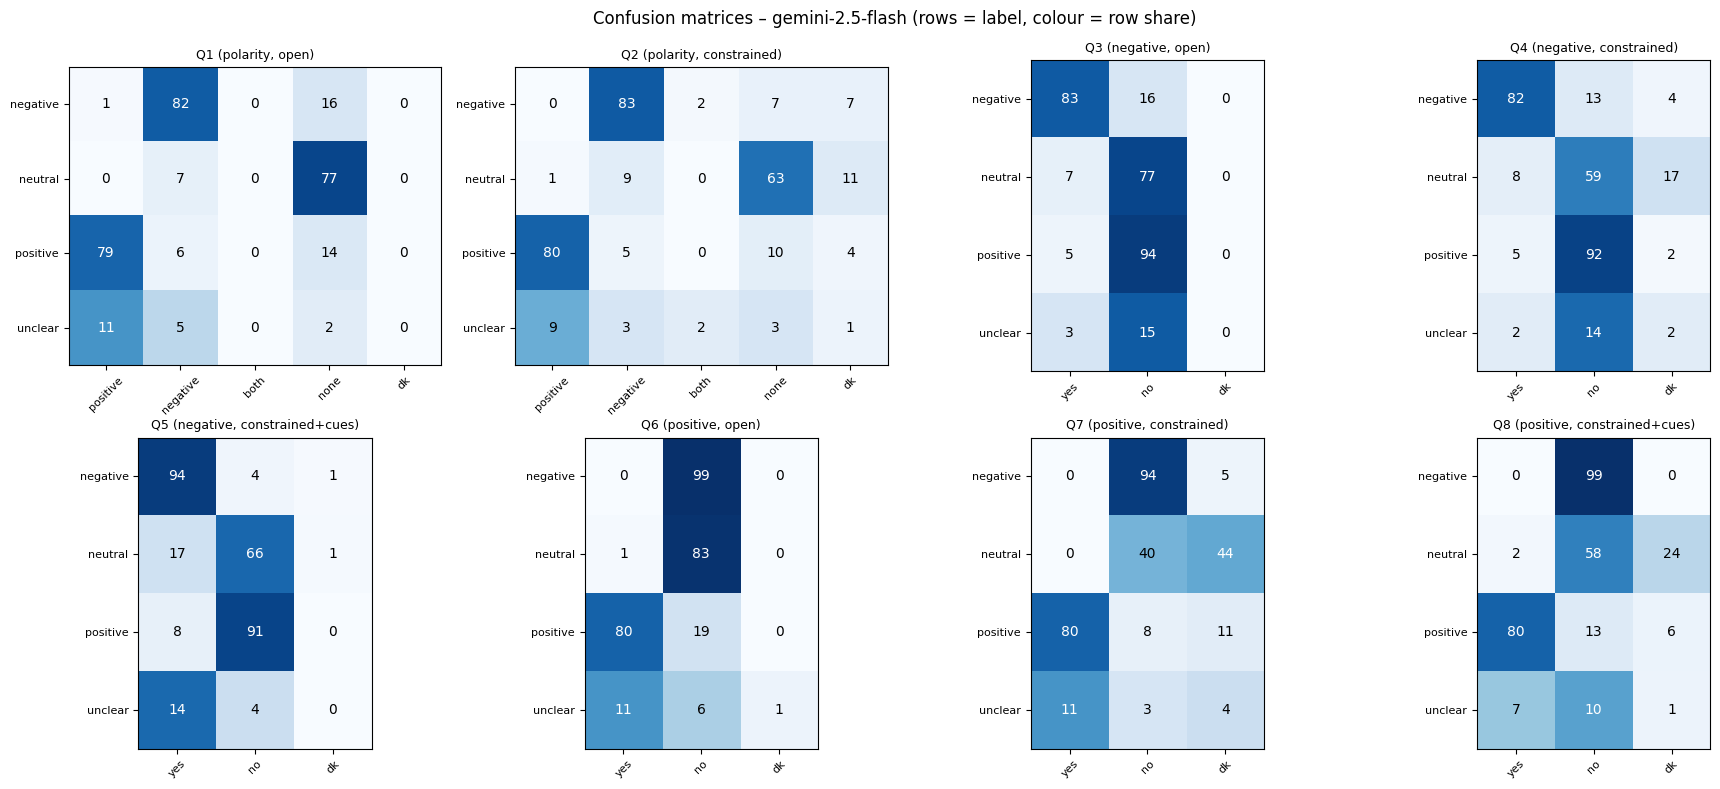

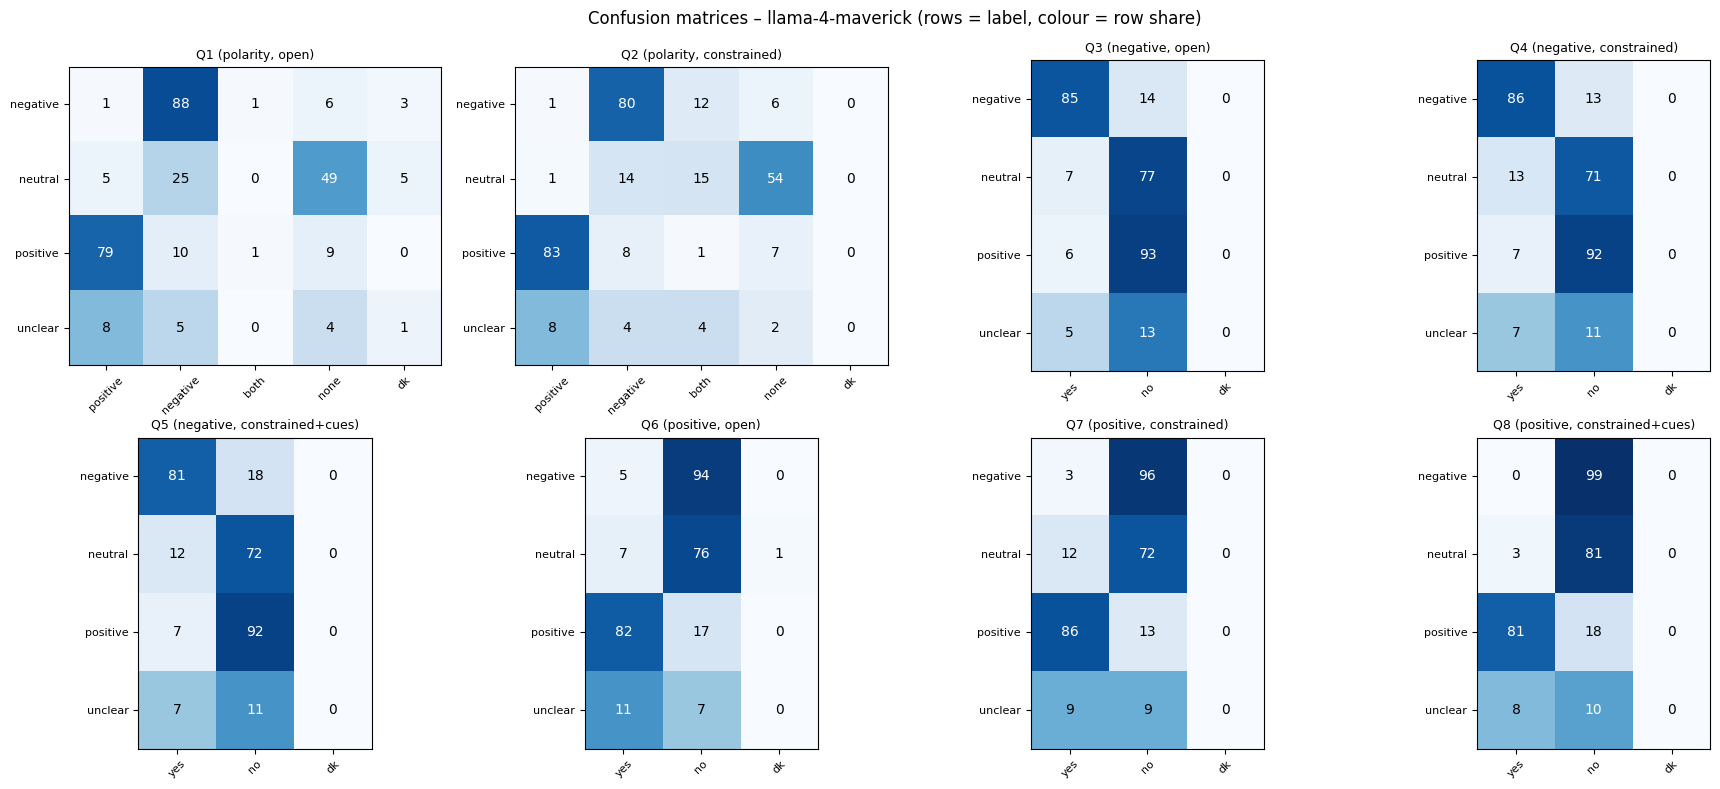

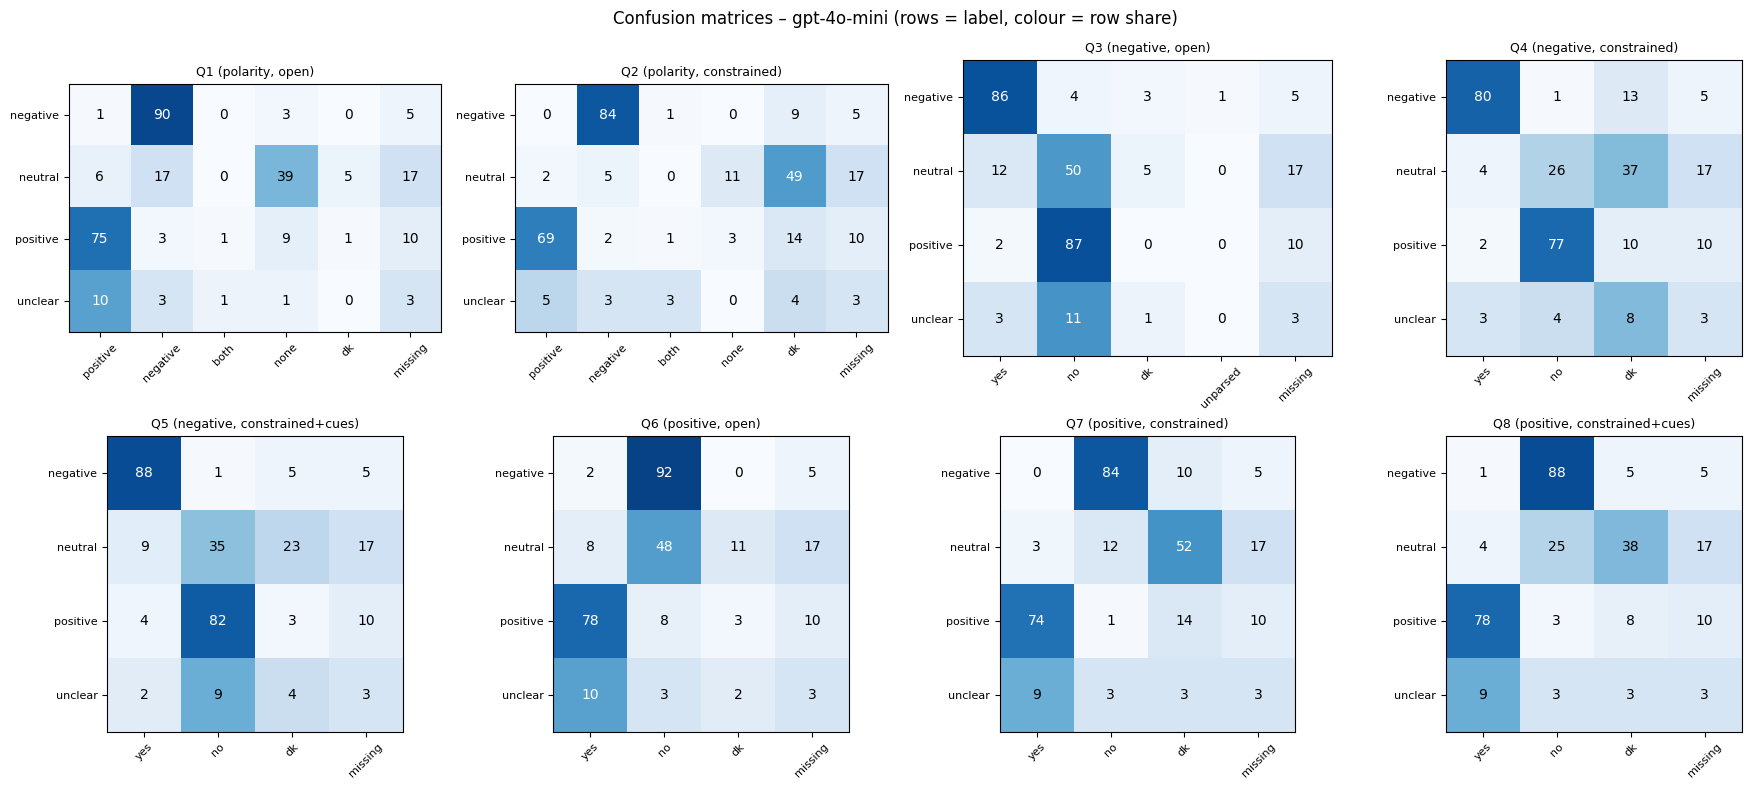

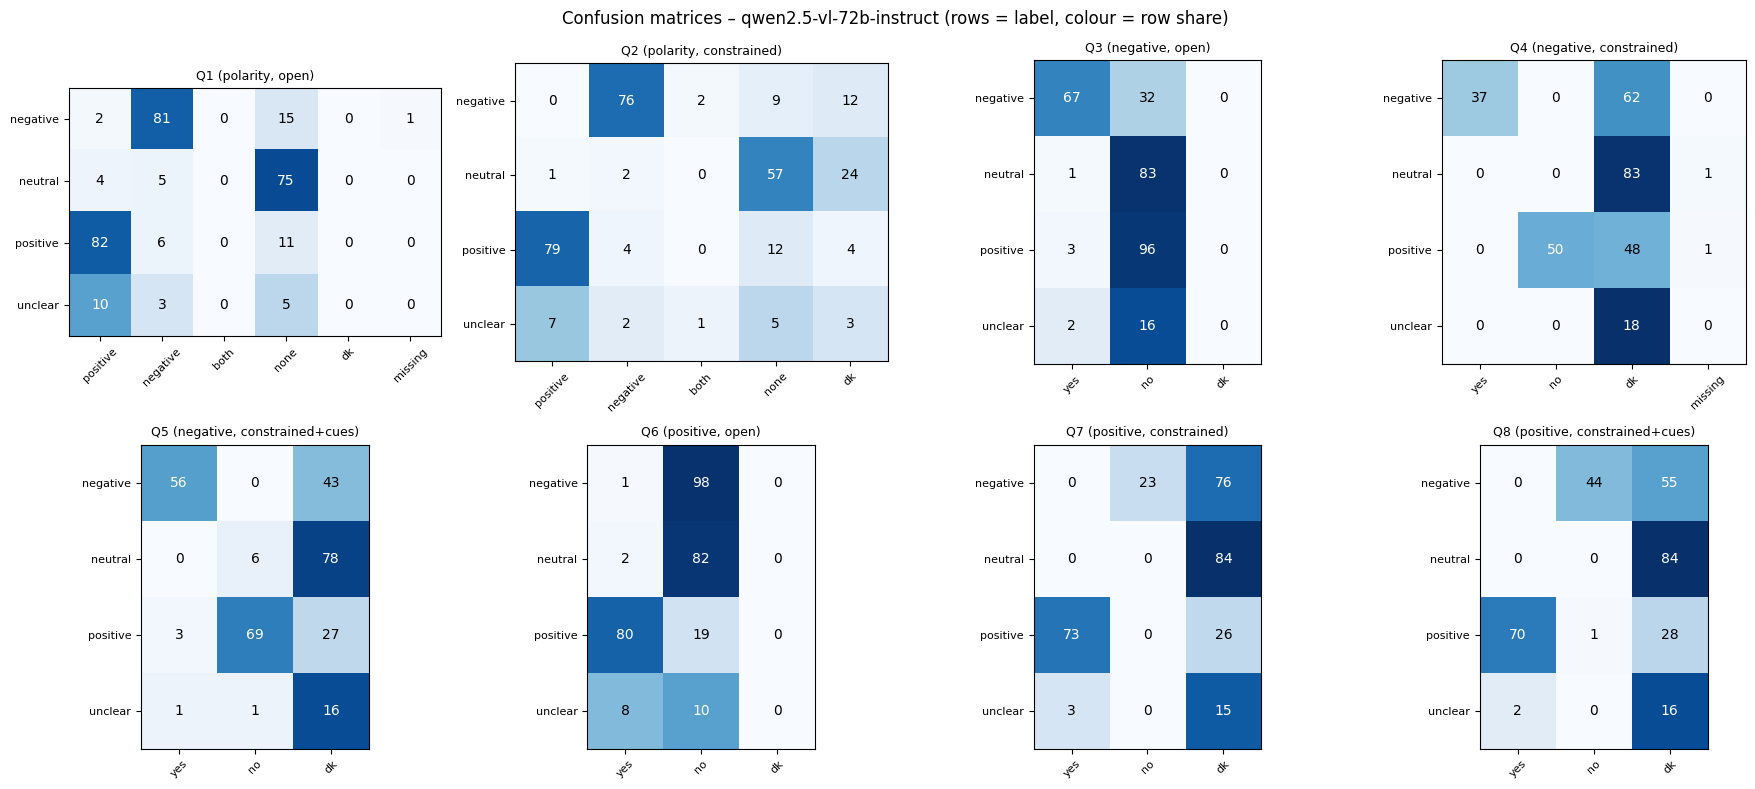

In [13]:
for m in MODELS:
    U.plot_confusions(long, m, OUTPUT_DIR / f"confusion_{U.safe_name(m)}.png")
plt.show()

**What is calculated:** For each model and question, label (rows, including *unclear*) × normalised answer (all available answers).

**Why:** It shows which errors drive each model's metrics.

**How to compare:** Correct cells should be dark. Compare the neutral rows between models in particular, since they are the hardest.

> **Result:** The models differ most on the neutral images. In Q1, Gemini and Qwen call 77 and 75 of the 84 neutral images "none", while Llama calls 25 of them negative. In Q2, GPT answers DK for 49 neutral images.

## 5. Model comparison
### 5a. Exact McNemar test between models, per question (common subset, Holm-corrected within question)

In [14]:
mcm = U.mcnemar_models(long[long.in_common])
mcm.to_csv(OUTPUT_DIR / "mcnemar_models.csv", index=False)
mcm.round(4)

,qid,model_a,model_b,n,acc_a,acc_b,only_a_correct,only_b_correct,p_value,p_holm
0,Q1,gemini-2.5-flash,llama-4-maverick,249,0.8474,0.7711,36,17,0.0127,0.0633
1,Q1,gemini-2.5-flash,gpt-4o-mini,249,0.8474,0.8153,27,19,0.3020,0.8736
2,Q1,gemini-2.5-flash,qwen2.5-vl-72b-instruct,249,0.8474,0.8474,8,8,1.0000,1.0000
3,Q1,llama-4-maverick,gpt-4o-mini,249,0.7711,0.8153,14,25,0.1081,0.4325
4,Q1,llama-4-maverick,qwen2.5-vl-72b-instruct,249,0.7711,0.8474,15,34,0.0094,0.0564
5,Q1,gpt-4o-mini,qwen2.5-vl-72b-instruct,249,0.8153,0.8474,18,26,0.2912,0.8736
6,Q2,gemini-2.5-flash,llama-4-maverick,250,0.8040,0.7680,26,17,0.2221,0.4441
7,Q2,gemini-2.5-flash,gpt-4o-mini,250,0.8040,0.6560,45,8,0.0000,0.0000
8,Q2,gemini-2.5-flash,qwen2.5-vl-72b-instruct,250,0.8040,0.7440,27,12,0.0237,0.0711
9,Q2,llama-4-maverick,gpt-4o-mini,250,0.7680,0.6560,43,15,0.0003,0.0015


**What is calculated:** For each question, an exact McNemar test for every pair of models on the common subset (images only model A gets right vs. only model B), Holm-corrected over the 6 pairs.

**Why:** The models answer the same images, so a paired test is the right way to decide whether two models really differ.

**How to compare:** `p_holm` < 0.05 means the two models differ on that question. `only_a_correct` vs. `only_b_correct` gives the direction.

> **Result:** On Q1 and Q3 no pair of models differs significantly, and on Q6 only Gemini beats GPT (p_holm = 0.036). On the constrained prompts almost every pair differs; for example on Q7 Llama alone is right on 64 images and GPT alone on 3 (p_holm < 0.001).

In [15]:
# Overall ranking: mean accuracy across the 8 questions (common subset)
rank = summary_common.pivot(index="model", columns="qid", values="accuracy")
rank["mean_acc"] = rank.mean(axis=1)
rank["mean_rank"] = summary_common.assign(r=summary_common.groupby("qid").accuracy.rank(ascending=False)) \
                                  .groupby("model").r.mean()
rank.sort_values("mean_acc", ascending=False).round(3)

qid,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,mean_acc,mean_rank
model,,,,,,,,,,
llama-4-maverick,0.771,0.768,0.904,0.887,0.872,0.916,0.924,0.936,0.872,1.938
gemini-2.5-flash,0.847,0.804,0.904,0.847,0.896,0.932,0.796,0.860,0.861,1.500
gpt-4o-mini,0.815,0.656,0.892,0.734,0.820,0.872,0.680,0.764,0.779,3.250
qwen2.5-vl-72b-instruct,0.847,0.744,0.872,0.343,0.484,0.924,0.360,0.428,0.625,3.312


**What is calculated:** The mean accuracy over the 8 questions and the mean rank of each model (common subset).

**Why:** A single summary number per model.

**How to compare:** Mean accuracy is dominated by large gaps (such as Qwen's DK answers), while mean rank counts every question equally. Read both, and do not over-interpret small differences (see the McNemar tests).

> **Result:** Llama has the highest mean accuracy (0.872), closely followed by Gemini (0.861), but Gemini has the better mean rank (1.5 vs. 1.9): Gemini wins more questions and Llama is more even. GPT (0.779) and Qwen (0.625) follow, mainly because of their DK answers.

### 5b. Agreement between models (Cohen's κ on the normalised answers, per question)

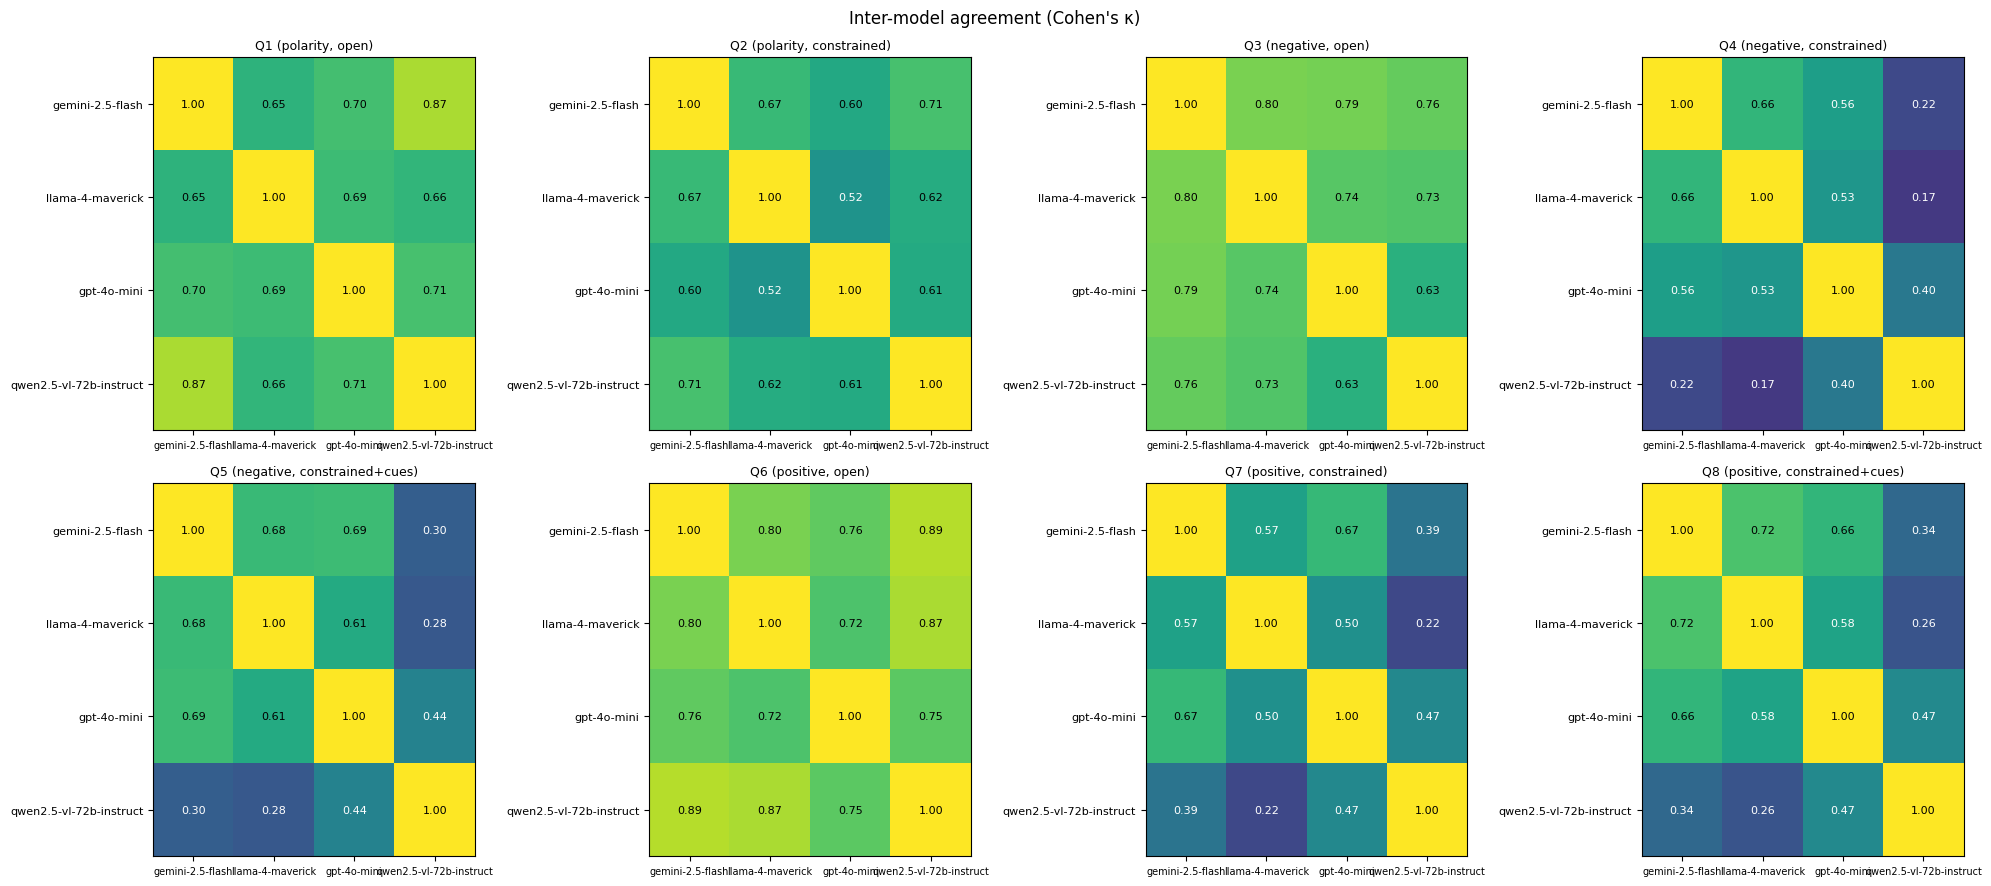

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, q in zip(axes.flat, U.QIDS):
    w = long[(long.qid == q) & (long.pred != "missing")].pivot(index="filename", columns="model", values="pred")
    mat = pd.DataFrame(index=MODELS, columns=MODELS, dtype=float)
    for a in MODELS:
        for b in MODELS:
            ok = w[[a, b]].dropna()
            mat.loc[a, b] = U.cohen_kappa(ok[a], ok[b])
    U.plot_heatmap(mat, f"{q} ({QMETA.loc[q, 'target']}, {QMETA.loc[q, 'style']})", ax, cmap="viridis", fontsize=8)
fig.suptitle("Inter-model agreement (Cohen's κ)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "agreement_between_models.png", dpi=150)
plt.show()

**What is calculated:** Cohen's κ between the normalised answers of every pair of models, for each question (answer vs. answer, not vs. the labels).

**Why:** It shows whether the models see the same thing in an image, or whether their behaviour is model-specific.

**How to compare:** High κ means the models agree on which images carry the emotion. Low κ on a question points to model-specific response styles. κ guide: < 0.4 fair, 0.4–0.6 moderate, 0.6–0.8 substantial, > 0.8 almost perfect agreement.

> **Result:** The models agree most on the open questions Q6 (κ 0.72–0.89) and Q1 (0.65–0.87) and least on the constrained prompts (Q4: 0.17–0.66), where different DK habits dominate.

## 6. Prompt-variant comparison per model
### 6a. Exact McNemar test between question variants (all available answers, Holm-corrected within model)

In [17]:
mcp = U.mcnemar_prompts(long)
mcp.to_csv(OUTPUT_DIR / "mcnemar_prompts.csv", index=False)
mcp.pivot(index="pair", columns="model", values=["acc_first", "acc_second", "p_holm"]).round(3)

acc_first                                                            acc_second                                                                p_holm                               \
model    gemini-2.5-flash gpt-4o-mini llama-4-maverick qwen2.5-vl-72b-instruct gemini-2.5-flash gpt-4o-mini llama-4-maverick qwen2.5-vl-72b-instruct gemini-2.5-flash gpt-4o-mini llama-4-maverick   
pair                                                                                                                                                                                                 
Q1 vs Q2            0.844       0.816            0.766                   0.847            0.801       0.656            0.770                   0.751            0.045       0.000            1.000   
Q3 vs Q4            0.901       0.892            0.904                   0.871            0.826       0.732            0.883                   0.311            0.000       0.000            0.952   
Q3 vs Q5            0.901       0.892            0.904                   0.872            0.890       0.820            0.869                   0.465            0.690       0.001            0.216   
Q4 vs Q5            0.826       0.732            0.883                   0.311            0.890       0.820            0.869                   0.464            0.019       0.000            1.000   
Q6 vs Q7            0.929       0.872            0.894                   0.922            0.759       0.680            0.901                   0.340            0.000       0.000            1.000   
Q6 vs Q8            0.929       0.872            0.894                   0.922            0.840       0.764            0.926                   0.404            0.000       0.000            0.216   
Q7 vs Q8            0.759       0.680            0.901                   0.340            0.840       0.764            0.926                   0.404            0.000       0.000            0.717   

                                  
model    qwen2.5-vl-72b-instruct  
pair                              
Q1 vs Q2                   0.000  
Q3 vs Q4                   0.000  
Q3 vs Q5                   0.000  
Q4 vs Q5                   0.000  
Q6 vs Q7                   0.000  
Q6 vs Q8                   0.000  
Q7 vs Q8                   0.001

**What is calculated:** Within each model, an exact McNemar test between prompt variants (all available answers, Holm-corrected over the 7 pairs).

**Why:** It shows whether the effect of the wording is the same for all models.

**How to compare:** `acc_first` vs. `acc_second` gives the direction, and `p_holm` < 0.05 means significant.

> **Result:** The prompt effect depends on the model. For Gemini, GPT and Qwen the open questions are significantly better than the constrained ones (e.g. Gemini Q6 0.93 vs. Q7 0.76), mostly because of DK answers. For Llama no prompt difference is significant (all p_holm ≥ 0.21).

### 6b. Consistency between questions
Polarity derived from the yes/no pairs: (negative?, positive?) = (yes, no) → negative, (no, yes) → positive, (no, no) → none, (yes, yes) → both.

In [18]:
data = U.add_derived(data)
dlong = U.derived_long(data)
dsum = U.question_metrics(dlong, n_boot=N_BOOT, seed=SEED)
cols = ["model", "qid", "n_scored", "dk_rate", "accuracy", "acc_answered", "acc_lo", "acc_hi", "macro_f1", "kappa"]
pol = pd.concat([summary_all[summary_all.target == "polarity"][cols], dsum[cols]])
pol.to_csv(OUTPUT_DIR / "polarity_incl_derived.csv", index=False)
pol.pivot(index="qid", columns="model", values="accuracy").reindex(U.POL_COLS).round(3)

model,gemini-2.5-flash,gpt-4o-mini,llama-4-maverick,qwen2.5-vl-72b-instruct
qid,,,,
Q1,0.844,0.816,0.766,0.847
Q2,0.801,0.656,0.770,0.752
"D(Q3,Q6)",0.848,0.776,0.823,0.809
"D(Q4,Q7)",0.670,0.608,0.809,0.254
"D(Q5,Q8)",0.762,0.692,0.819,0.376


**What is calculated:** A polarity derived from each yes/no pair (negative?, positive?), scored like Q1/Q2 (accuracy, all available answers).

**Why:** It tests whether two yes/no questions give a better polarity judgement than asking for the polarity directly.

**How to compare:** Compare the D(…) rows with Q1/Q2 within each model column.

> **Result:** For Llama, the polarity derived from the yes/no pairs (0.81–0.82) beats its direct answers (0.77). For Gemini, Q1 and D(Q3,Q6) are on par (0.84–0.85). With the constrained pairs the derived polarity collapses for Qwen (0.25–0.38) and GPT (0.61–0.69) because of DK.

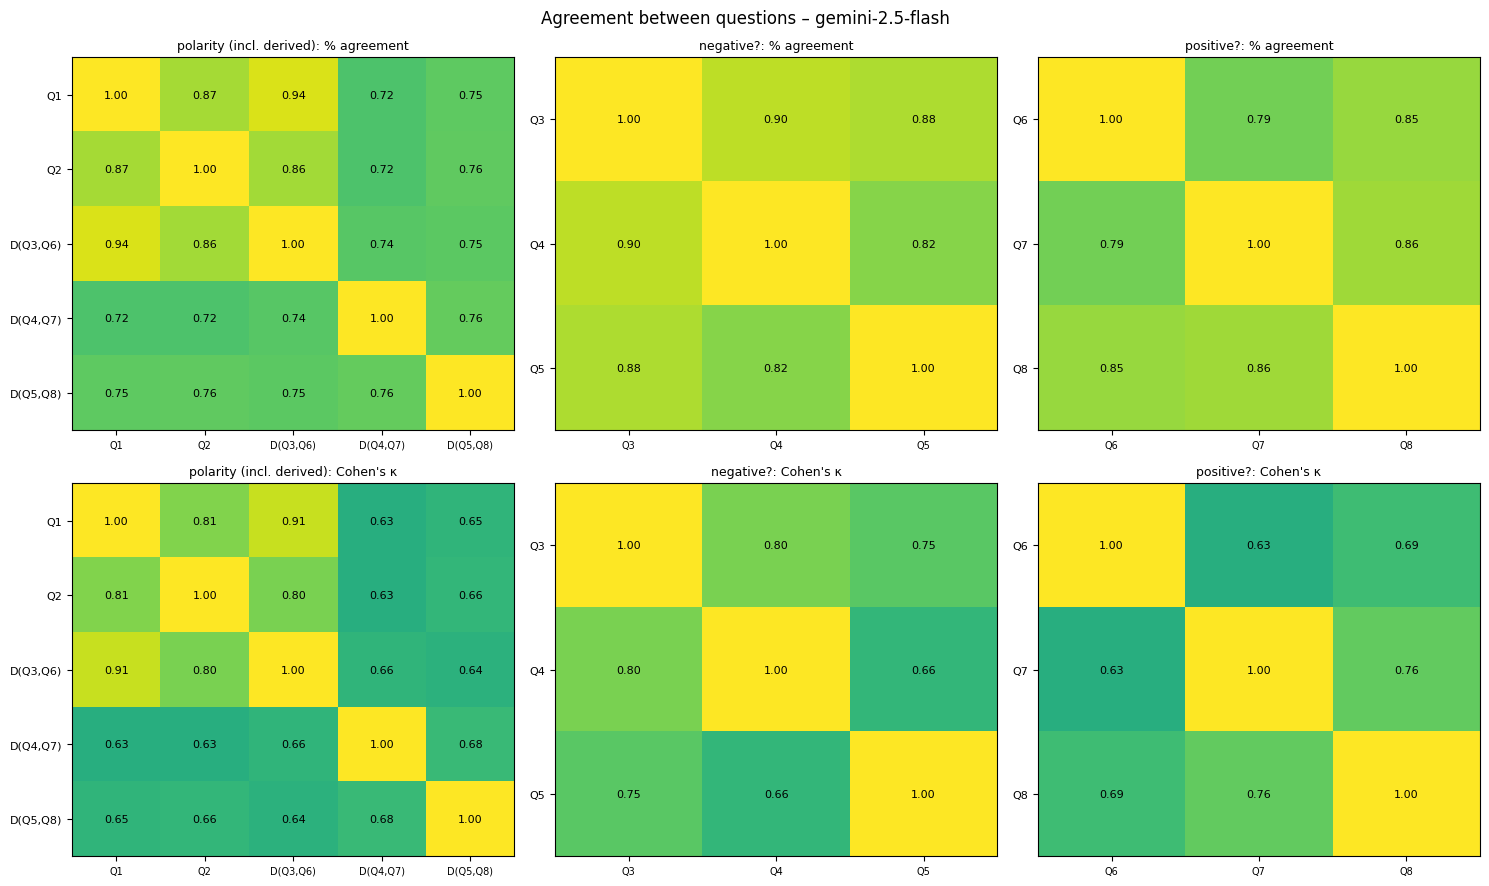

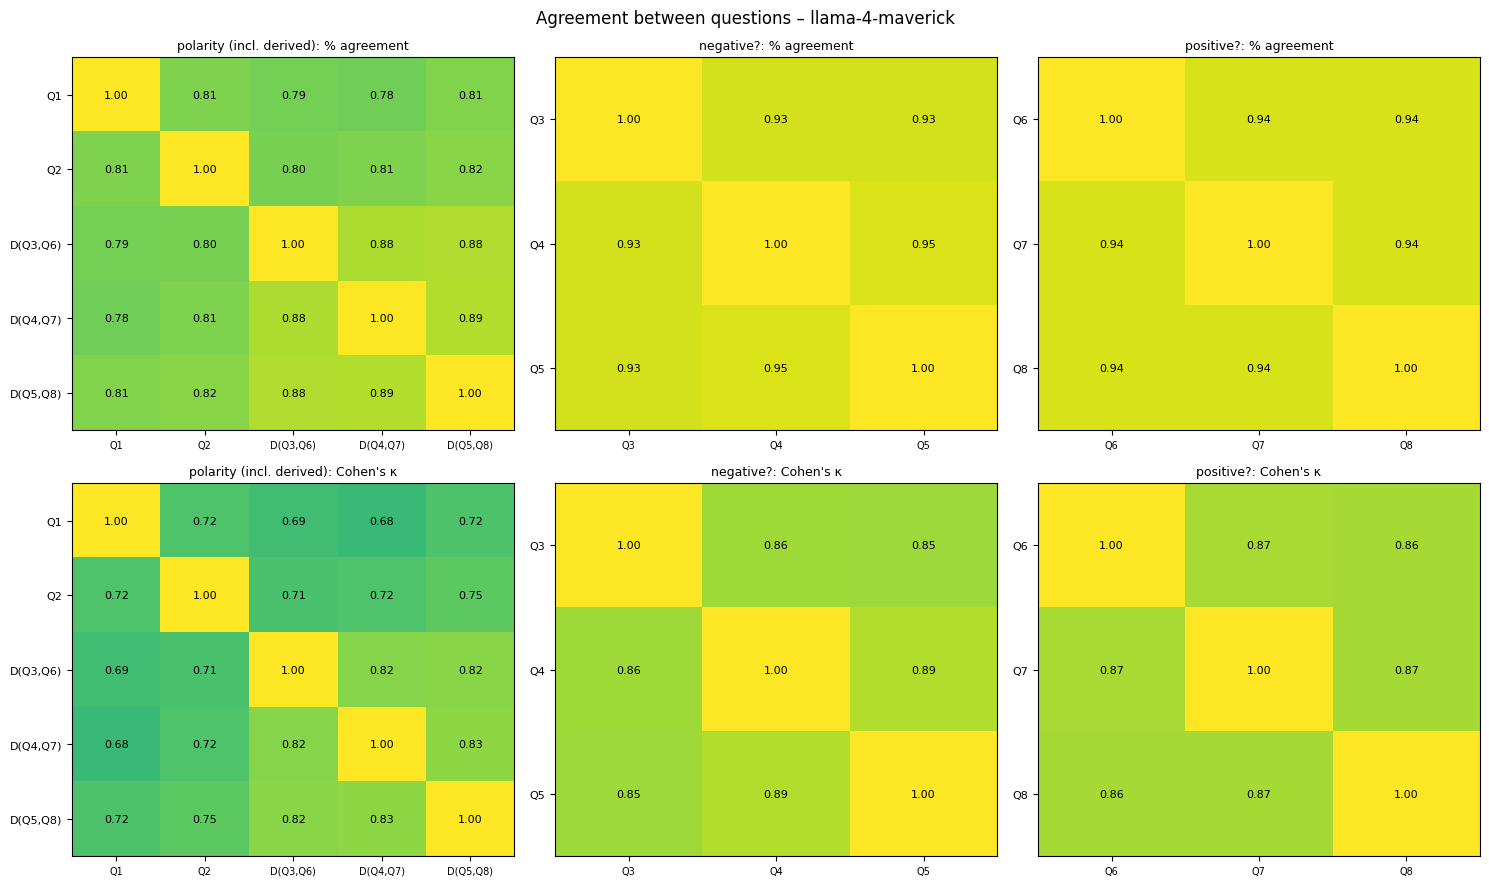

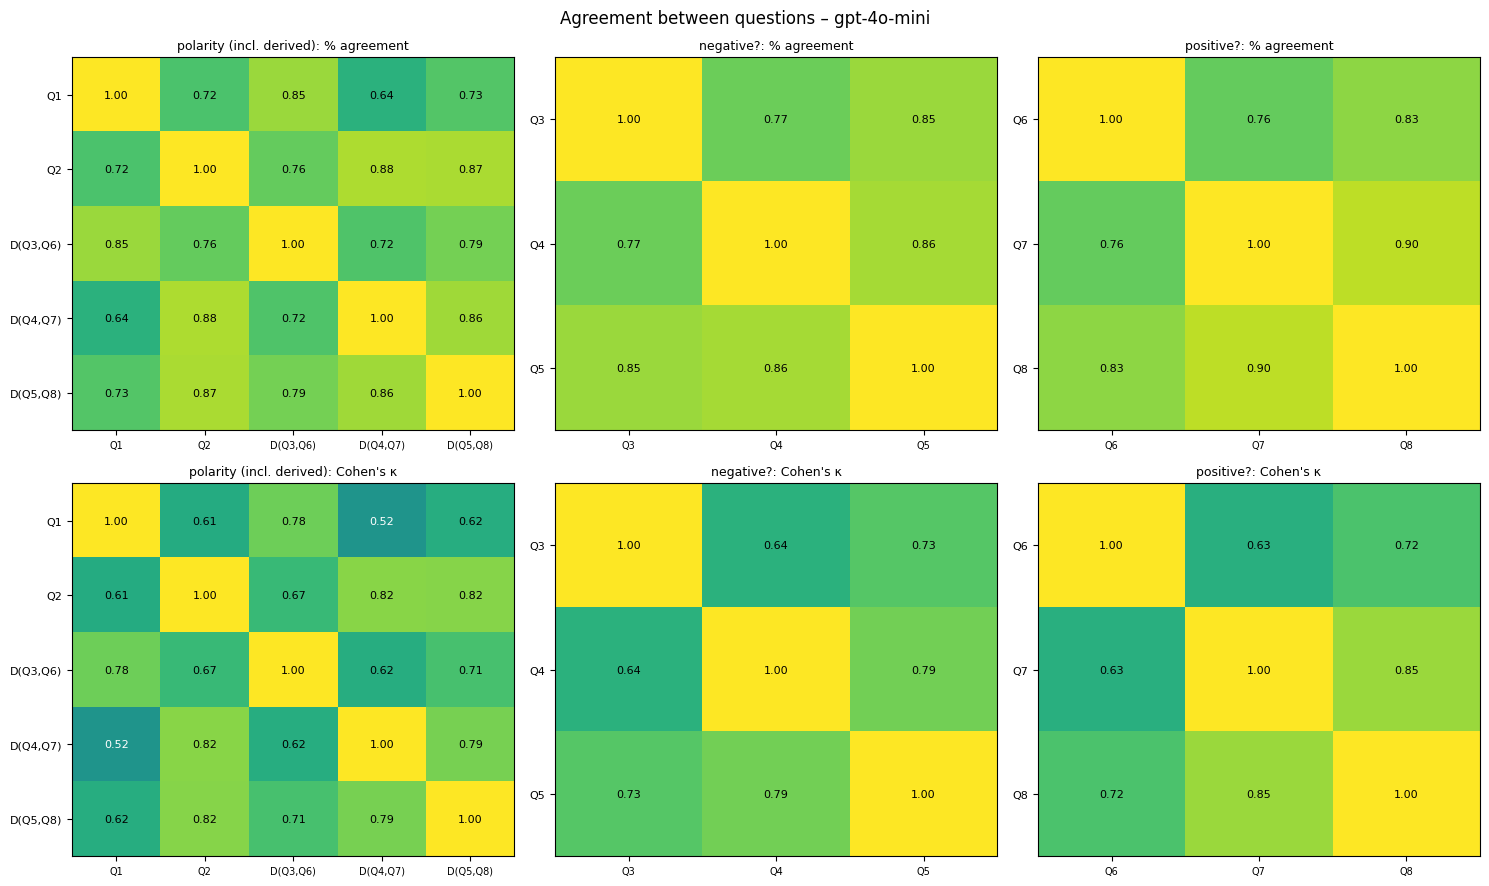

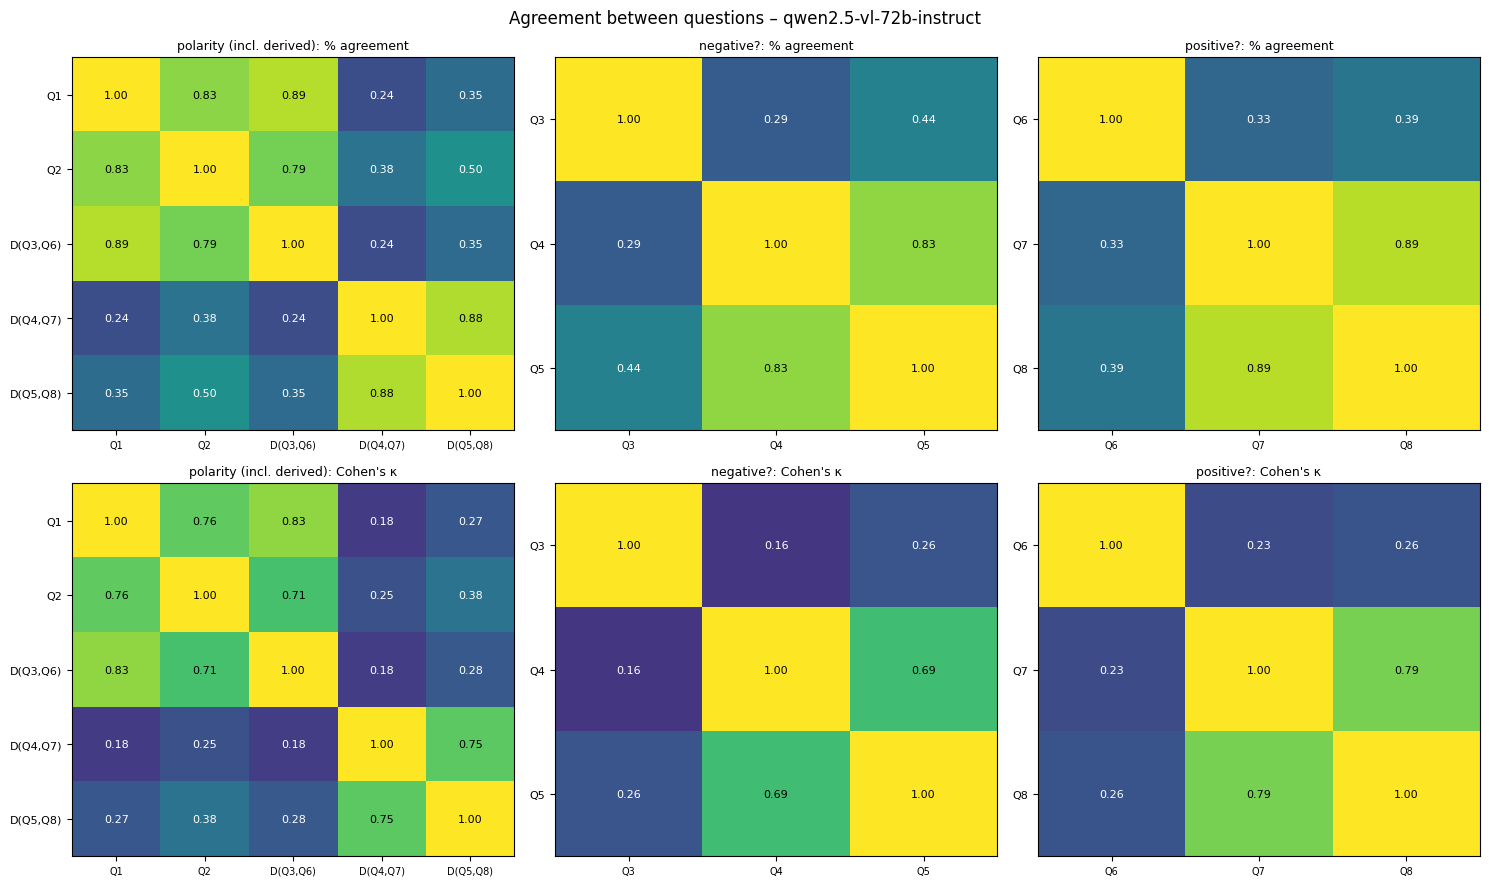

In [19]:
for m in MODELS:
    U.plot_agreement(data, m, OUTPUT_DIR / f"agreement_{U.safe_name(m)}.png")
plt.show()

**What is calculated:** For each model, pairwise % agreement and κ between its answers to the different questions.

**Why:** It measures how stable each model's judgement is under rephrasing.

**How to compare:** κ close to 1 means the wording does not matter; low κ means the model changes its answer with the prompt. κ guide: < 0.4 fair, 0.4–0.6 moderate, 0.6–0.8 substantial, > 0.8 almost perfect agreement.

> **Result:** Llama gives the most stable answers (κ 0.85–0.89 within the negative and positive groups). For Qwen the open and constrained variants hardly agree (Q3 vs. Q4 κ 0.16, Q6 vs. Q7 0.23) because of DK.

In [20]:
contra = U.contradictions(data)
contra.to_csv(OUTPUT_DIR / "contradictions.csv", index=False)
contra

,model,polarity_q,neg_q,pos_q,pol=positive & neg=yes,pol=negative & pos=yes,pol=none & (neg|pos)=yes,pol=positive & pos=no,pol=negative & neg=no
0,gemini-2.5-flash,Q1,Q3,Q6,1,0,7,2,7
1,gemini-2.5-flash,Q1,Q4,Q7,1,0,5,1,6
2,gemini-2.5-flash,Q1,Q5,Q8,10,0,30,8,1
3,gemini-2.5-flash,Q2,Q3,Q6,0,0,5,3,7
4,gemini-2.5-flash,Q2,Q4,Q7,0,0,3,0,5
5,gemini-2.5-flash,Q2,Q5,Q8,6,0,13,5,0
6,llama-4-maverick,Q1,Q3,Q6,2,8,9,6,32
7,llama-4-maverick,Q1,Q4,Q7,5,5,18,5,26
8,llama-4-maverick,Q1,Q5,Q8,4,2,6,9,30
9,llama-4-maverick,Q2,Q3,Q6,1,3,7,3,16


**What is calculated:** For each model, the counts of logically inconsistent combinations between a polarity answer (Q1/Q2) and a yes/no pair.

**Why:** It checks each model's internal consistency.

**How to compare:** The first three columns are hard contradictions and the last two soft ones (different thresholds). Zeros can also come from DK answers (e.g. Qwen on Q4/Q7), which take part in no combination.

> **Result:** Hard contradictions mostly stay at 0–10 per combination. The largest are Gemini's Q1 vs. the cue questions (30 images with "none" in Q1 but "yes" in Q5 or Q8) and Llama's Q1 vs. Q4/Q7 (18). Llama also most often says "negative" in Q1 but "no" to the negative question (26–32 images).

## 7. Breakdown by subfolder

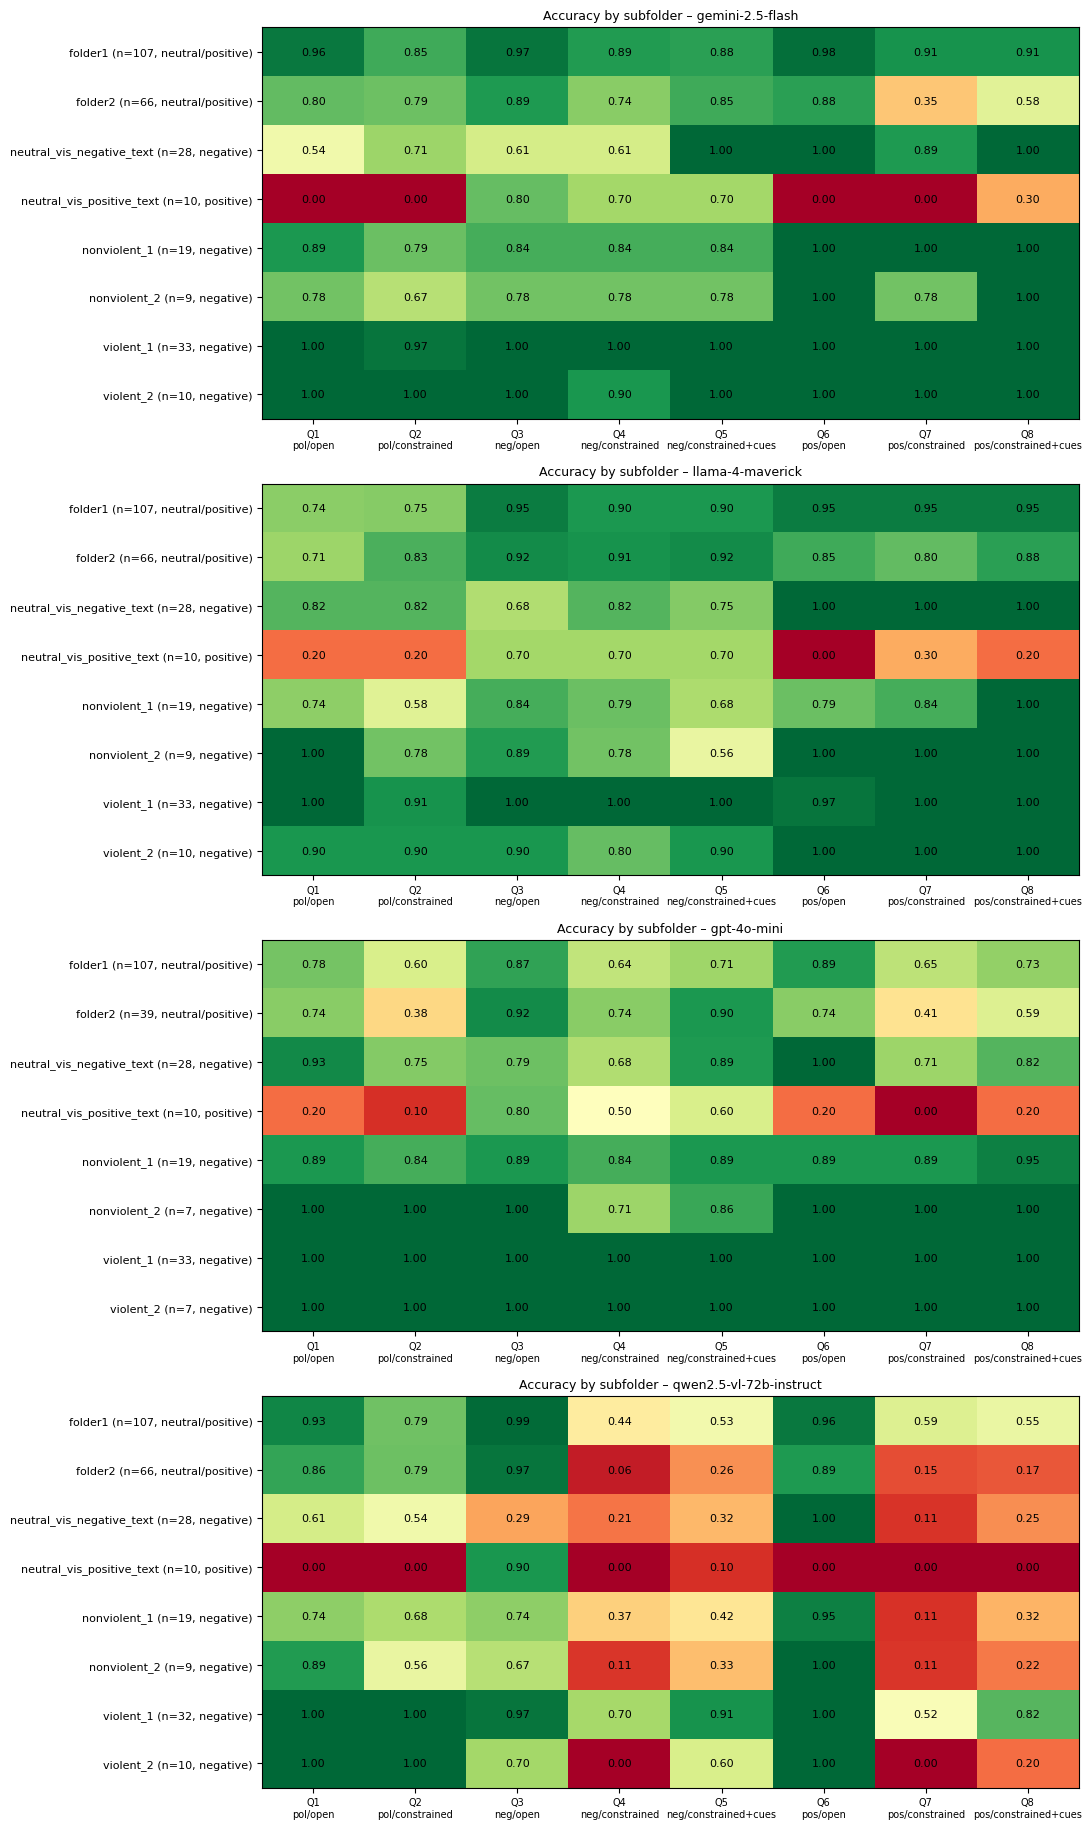

In [21]:
fig, axes = plt.subplots(len(MODELS), 1, figsize=(11, 4.6 * len(MODELS)))
for ax, m in zip(np.atleast_1d(axes), MODELS):
    acc = U.subfolder_accuracy(long, m)
    acc.round(3).to_csv(OUTPUT_DIR / f"subfolder_accuracy_{U.safe_name(m)}.csv")
    U.plot_heatmap(acc, f"Accuracy by subfolder – {m}", ax, xlabels=[U.qlabel(q) for q in acc.columns])
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "subfolder_accuracy.png", dpi=150)
plt.show()

**What is calculated:** Accuracy per subfolder and question, one heatmap per model.

**Why:** The subfolders encode how the emotion is conveyed, so this shows which stimulus types are hard for which model.

**How to compare:** Compare the same row across models. Small subfolders (n = 9–10) are noisy.

> **Result:** Every model fails when positive emotion is carried only by the text (`neutral_vis_positive_text`: Q1/Q2/Q6 at 0.00–0.20 for all models). Violent images are recognised almost perfectly by all models, except Qwen on the constrained prompts.

In [22]:
# Model x question accuracy per subfolder and label (all available answers)
by_label = long[long.scored].pivot_table(index=["subfolder", "emotion", "model"], columns="qid",
                                         values="correct", aggfunc="mean").round(2)
by_label.to_csv(OUTPUT_DIR / "accuracy_by_subfolder_label.csv")
by_label

qid                                                           Q1    Q2    Q3    Q4    Q5    Q6    Q7    Q8
subfolder                 emotion  model                                                                  
folder1                   neutral  gemini-2.5-flash         0.92  0.62  0.92  0.70  0.72  0.98  0.78  0.82
                                   gpt-4o-mini              0.48  0.05  0.65  0.18  0.30  0.75  0.18  0.32
                                   llama-4-maverick         0.45  0.40  0.88  0.75  0.75  0.95  0.92  0.95
                                   qwen2.5-vl-72b-instruct  0.85  0.48  0.98  0.00  0.02  0.98  0.00  0.00
                          positive gemini-2.5-flash         0.99  0.99  1.00  1.00  0.97  0.99  0.99  0.96
                                   gpt-4o-mini              0.96  0.93  1.00  0.93  0.96  0.97  0.94  0.97
                                   llama-4-maverick         0.91  0.96  1.00  0.99  0.99  0.96  0.97  0.96
                                   qwen2.5-vl-72b-instruct  0.99  0.97  1.00  0.70  0.84  0.96  0.94  0.88
folder2                   neutral  gemini-2.5-flash         0.91  0.86  0.91  0.70  0.84  1.00  0.20  0.57
                                   gpt-4o-mini              0.74  0.33  0.89  0.70  0.85  0.67  0.19  0.44
                                   llama-4-maverick         0.70  0.86  0.95  0.93  0.95  0.86  0.80  0.98
                                   qwen2.5-vl-72b-instruct  0.93  0.86  1.00  0.00  0.11  0.98  0.00  0.00
                          positive gemini-2.5-flash         0.59  0.64  0.86  0.82  0.86  0.64  0.64  0.59
                                   gpt-4o-mini              0.75  0.50  1.00  0.83  1.00  0.92  0.92  0.92
                                   llama-4-maverick         0.73  0.77  0.86  0.86  0.86  0.82  0.82  0.68
                                   qwen2.5-vl-72b-instruct  0.73  0.64  0.91  0.18  0.55  0.73  0.45  0.50
neutral_vis_negative_text negative gemini-2.5-flash         0.54  0.71  0.61  0.61  1.00  1.00  0.89  1.00
                                   gpt-4o-mini              0.93  0.75  0.79  0.68  0.89  1.00  0.71  0.82
                                   llama-4-maverick         0.82  0.82  0.68  0.82  0.75  1.00  1.00  1.00
                                   qwen2.5-vl-72b-instruct  0.61  0.54  0.29  0.21  0.32  1.00  0.11  0.25
neutral_vis_positive_text positive gemini-2.5-flash         0.00  0.00  0.80  0.70  0.70  0.00  0.00  0.30
                                   gpt-4o-mini              0.20  0.10  0.80  0.50  0.60  0.20  0.00  0.20
                                   llama-4-maverick         0.20  0.20  0.70  0.70  0.70  0.00  0.30  0.20
                                   qwen2.5-vl-72b-instruct  0.00  0.00  0.90  0.00  0.10  0.00  0.00  0.00
nonviolent_1              negative gemini-2.5-flash         0.89  0.79  0.84  0.84  0.84  1.00  1.00  1.00
                                   gpt-4o-mini              0.89  0.84  0.89  0.84  0.89  0.89  0.89  0.95
                                   llama-4-maverick         0.74  0.58  0.84  0.79  0.68  0.79  0.84  1.00
                                   qwen2.5-vl-72b-instruct  0.74  0.68  0.74  0.37  0.42  0.95  0.11  0.32
nonviolent_2              negative gemini-2.5-flash         0.78  0.67  0.78  0.78  0.78  1.00  0.78  1.00
                                   gpt-4o-mini              1.00  1.00  1.00  0.71  0.86  1.00  1.00  1.00
                                   llama-4-maverick         1.00  0.78  0.89  0.78  0.56  1.00  1.00  1.00
                                   qwen2.5-vl-72b-instruct  0.89  0.56  0.67  0.11  0.33  1.00  0.11  0.22
violent_1                 negative gemini-2.5-flash         1.00  0.97  1.00  1.00  1.00  1.00  1.00  1.00
                                   gpt-4o-mini              1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
                                   llama-4-maverick         1.00  0.91  1.00  1.00  1.00  0.97  1.00  1.00
                                   qwen2.

**What is calculated:** Accuracy per subfolder, label and model.

**Why:** `folder1`/`folder2` mix positive and neutral images, and the neutral ones separate the models.

**How to compare:** Compare the neutral rows between models.

> **Result:** The neutral images in `folder1` separate the models: in Q2 GPT gets only 5% of them right (mostly DK), and Qwen 0% on Q4/Q7/Q8, while Llama stays at 0.75–0.95 on all yes/no questions.

## 8. Images labelled *unclear* (not scored)

In [23]:
unc = data[data.emotion == "unclear"]
print(f"{unc.filename.nunique()} unclear images")
pd.concat({q: unc.groupby("model")[q + "_norm"].value_counts().unstack(fill_value=0) for q in U.POL_COLS + U.QIDS[2:]},
          names=["qid"]).fillna(0).astype(int)

18 unclear images


both  dk  missing  negative  none  positive  no  yes
qid      model                                                                        
Q1       gemini-2.5-flash            0   0        0         5     2        11   0    0
         gpt-4o-mini                 1   0        3         3     1        10   0    0
         llama-4-maverick            0   1        0         5     4         8   0    0
         qwen2.5-vl-72b-instruct     0   0        0         3     5        10   0    0
Q2       gemini-2.5-flash            2   1        0         3     3         9   0    0
         gpt-4o-mini                 3   4        3         3     0         5   0    0
         llama-4-maverick            4   0        0         4     2         8   0    0
         qwen2.5-vl-72b-instruct     1   3        0         2     5         7   0    0
D(Q3,Q6) gemini-2.5-flash            0   1        0         2     4        11   0    0
         gpt-4o-mini                 0   3        3         3     0         9   0    0
         llama-4-maverick            2   0        0         3     4         9   0    0
         qwen2.5-vl-72b-instruct     0   0        0         2     8         8   0    0
D(Q4,Q7) gemini-2.5-flash            0   4        0         2     1        11   0    0
         gpt-4o-mini                 0   8        3         3     0         4   0    0
         llama-4-maverick            2   0        0         5     4         7   0    0
         qwen2.5-vl-72b-instruct     0  18        0         0     0         0   0    0
D(Q5,Q8) gemini-2.5-flash            3   1        0        10     0         4   0    0
         gpt-4o-mini                 0   5        3         2     1         7   0    0
         llama-4-maverick            1   0        0         6     4         7   0    0
         qwen2.5-vl-72b-instruct     0  18        0         0     0         0   0    0
Q3       gemini-2.5-flash            0   0        0         0     0         0  15    3
         gpt-4o-mini                 0   1        3         0     0         0  11    3
         llama-4-maverick            0   0        0         0     0         0  13    5
         qwen2.5-vl-72b-instruct     0   0        0         0     0         0  16    2
Q4       gemini-2.5-flash            0   2        0         0     0         0  14    2
         gpt-4o-mini                 0   8        3         0     0         0   4    3
         llama-4-maverick            0   0        0         0     0         0  11    7
         qwen2.5-vl-72b-instruct     0  18        0         0     0         0   0    0
Q5       gemini-2.5-flash            0   0        0         0     0         0   4   14
         gpt-4o-mini                 0   4        3         0     0         0   9    2
         llama-4-maverick            0   0        0         0     0         0  11    7
         qwen2.5-vl-72b-instruct     0  16        0         0     0         0   1    1
Q6       gemini-2.5-flash            0   1        0         0     0         0   6   11
         gpt-4o-mini                 0   2        3         0     0         0   3   10
         llama-4-maverick            0   0        0         0     0         0   7   11
         qwen2.5-vl-72b-instruct     0   0        0         0     0         0  10    8
Q7       gemini-2.5-flash            0   4        0         0     0         0   3   11
         gpt-4o-mini                 0   3        3         0     0         0   3    9
         llama-4-maverick            0   0        0         0     0         0   9    9
         qwen2.5-vl-72b-instruct     0  15        0         0     0         0   0    3
Q8       gemini-2.5-flash            0   1        0         0     0         0  10    7
         gpt-4o-mini                 0   3        3         0     0         0   3    9
         llama-4-maverick            0   0        0         0     0         0  10    8
         qwen2.5-vl-72b-instruct     0  16        0         0     0         0   0    2

**What is calculated:** The answer distribution for the 18 *unclear* images, per model and question (not scored).

**Why:** It shows whether a model signals uncertainty on ambiguous images.

**How to compare:** Many "none"/"dk" answers mean the ambiguity is recognised; a positive/negative split means the model commits anyway.

> **Result:** In Q1 all models mostly commit to positive or negative (only 1–5 "none"). Uncertainty is expressed mainly through DK on the constrained prompts, where Qwen answers DK for 15–18 of the 18 images.

## 9. Error inspection

In [24]:
# Images that most models get wrong (summed over all questions)
err = (long[long.scored].groupby(["filename", "emotion", "subfolder", "model"])["correct"]
       .agg(lambda x: int((1 - x).sum())).unstack("model"))
err["total_wrong"] = err.sum(axis=1)
err = err.sort_values("total_wrong", ascending=False)
err.to_csv(OUTPUT_DIR / "per_image_errors.csv")
err.head(25)

,,model,gemini-2.5-flash,gpt-4o-mini,llama-4-maverick,qwen2.5-vl-72b-instruct,total_wrong
filename,emotion,subfolder,,,,,
790356_01.jpg,positive,neutral_vis_positive_text,8.0,8.0,8.0,8.0,32.0
775034_01.jpg,positive,neutral_vis_positive_text,8.0,6.0,8.0,7.0,29.0
501521.jpeg,positive,neutral_vis_positive_text,6.0,6.0,8.0,7.0,27.0
790342.jpg,positive,neutral_vis_positive_text,6.0,7.0,5.0,7.0,25.0
512463.jpeg,positive,folder2,8.0,NaN,8.0,8.0,24.0
512598.jpeg,positive,folder2,8.0,NaN,8.0,8.0,24.0
806772_04.jpg,negative,nonviolent_1,4.0,7.0,5.0,7.0,23.0
775190_01.jpg,positive,folder1,6.0,7.0,3.0,7.0,23.0
514372.jpeg,positive,folder2,8.0,NaN,8.0,7.0,23.0


**What is calculated:** For each image and model, the number of wrong answers (out of 8), and the total over the models.

**Why:** Images that all models get wrong are either genuinely hard or possibly mislabelled.

**How to compare:** Look first at the images at the top, in the image and in the raw answers.

> **Result:** 790356_01.jpg (`neutral_vis_positive_text`, labelled positive) is wrong for all four models in all 8 questions. The top of the list is dominated by `neutral_vis_positive_text` and positive `folder2` images, which are candidates for a label check.

In [25]:
# Raw answers of all models for one image and one question
fname, q = err.index[0][0], "Q2"
long[(long.filename == fname) & (long.qid == q)][["model", "emotion", "truth", "pred", "raw"]]

,model,emotion,truth,pred,raw
1323,gemini-2.5-flash,positive,positive,negative,Negative.
1623,llama-4-maverick,positive,positive,negative,"The image depicts a young girl with a somber expression, accompanied by a quote in Hungarian that translates to ""I didn't turn my head because I was crying because someone put something into my dr..."
1923,gpt-4o-mini,positive,positive,negative,Negative
2223,qwen2.5-vl-72b-instruct,positive,positive,negative,negative


**What is calculated:** The raw answers of all models for one image and question (by default the hardest image and Q2; change `fname`/`q`).

**Why:** It shows *why* the models disagree with the label.

**How to compare:** Read the models' reasoning against the label.

> **Result:** All four models call 790356_01.jpg negative. Llama's answer shows why: it reads the Hungarian text as "I didn't turn my head because I was crying…", so the label *positive* may deserve a second look.